# Notes

### Features 
- **HighBp:** Hipertansiyon durumu
- **HighChol:** Yüksek Kolesterol durumu
- **CholCheck:** Son 5 yılda kolesterol kontrolü yapılıp yapılmadığı
- **BMI:** Vücut Kitle İndeksi
- **Smoker:** Sigara kullanımı
- **Stroke:** Daha önce inme geçirip geçirmediği
- **HeartDiseaseorAttack:** Daha önce kalp krizi geçirip geçirmediği
- **PhysActivity:** Fiziksel aktivite yapılıp yapılmadığı
- **Fruits:** Günde en az 1 meyve tüketimi
- **Veggies:** Günde en az 1 sebze tüketimi
- **HvyAlcoholConsump:** Aşırı alkol kullanımı
- **AnyHealthcare:** Sağlık sigortası varlığı
- **NoDocbcCost:** Maddi imkansızlıktan dolayı doktora gidememe durumu
- **GenHlth:** Genel sağlık durumu değerlendirmesi (1: Mükemmel - 5: Çok Kötü)
- **MentHlth:** Son 30 günde mental sağlığın kötü olduğu gün sayısı
- **PhysHlth:** Son 30 günde fiziksel sağlığın kötü olduğu gün sayısı
- **DiffWalk:** Yürürken veya merdiven çıkarken zorlanma durumu
- **Sex:** Cinsiyet
- **Age:** Yaş grubu
- **Education:** Eğitim durumu
- **Income:** Yıllık gelir grubu

---

### EDA
- **Fazla Alkol Tüketimi ve Diyabet İlişkisi:**
  - İki değişken arasında negatif bir korelasyon gözlemlenmiştir.
    - Diyabet teşhisi konulan hastaların doktor tavsiyesiyle alkolü kesmesi veya ciddi oranda azaltması.
    - Anketlerde ağır alkol kullandığını belirten kitlenin genelde genç yaş grubunda olması ve henüz diyabet geliştirmemiş olmaları.
- **Genel Sağlık Derecesi:**
  - Diyabet ile yüksek pozitif korelasyona sahiptir. Diyabetli bireyler kendi sağlıklarını belirgin şekilde kötü (4 veya 5) olarak puanlamaktadır.
  - GenHlth ile PhysHlth arasındaki yüksek korelasyon verinin iç tutarlılığını doğrulamaktadır.
- **Gelir Düzeyi:**
  - Diyabet ile negatif korelasyona sahiptir. Sosyoekonomik düzeyi yüksek bireylerin işlenmemiş kaliteli gıdaya erişimi, spor alışkanlığı ve düzenli sağlık takibi imkanları daha fazla olduğu için bu ilişki belirgindir.
- **Meyve/Sebze Tüketimi:**
  - Hedef değişken üzerinde doğrudan ayırt edici etkisi oldukça düşüktür.
- **Vücut Kitle İndeksi:**
  - Özellikle genç ve orta yaş gruplarında diyabet hastalarının ortalama BMI değerleri 31.8 - 35.0 gibi oldukça yüksek seviyelerdedir. Kilo artışı ve obezitenin diyabetle doğrudan ilişkili olduğu görülmüştür.
  - Tüm yaş gruplarında sağlıklı bireylerin ortalama BMI değerleri 25.5 - 28.5 aralığındayken, Diyabet sınıfına geçildiğinde ortalama BMI doğrudan 30'un üzerine fırlamaktadır.
  - İleri yaşlarda ortalama BMI seviyesindeki düşüş kemik erimesi ve kas kaybı ile açıklanabilir.
- **Sınıf Dengesizliği:**
  - Hedef değişkende sınıf dengesizliği bulunmaktadır. Bu durum modelleme aşamasında class_weight düzenlemeleri ve doğru doğrulama metrikleri Recall, ROC-AUC kullanılarak çözülmeye çalışılmıştır.

---

### Preprocessing
- **Outlier:** Aykırı değer temizliği yapılması mantıklı olan tek nitelik `BMI` değişkenidir. IQR yöntemi kullanılarak aykırı değerler veri setinden ayıklanmıştır.
- **Missing Value:** Veri setinde eksik değer bulunmamaktadır.
- **Encoding:** Kategorik değişkenler veri setinde zaten sayısal olarak kodlanmış durumdadır.
- **Scaling:** Ağaç tabanlı modeller ağırlıklı olarak kullanılacağı için sütunlarda ölçeklendirme yapılmasına gerek duyulmamıştır.

---

### Modelling
- Projede sınıflandırma problemi için ağaç tabanlı makine öğrenmesi algoritmaları, derin öğrenme tabanlı bir mimari ve topluluk öğrenme yöntemleri kullanılmıştır.
- **Kullanılan Algoritmalar:** XGBoost, Random Forest, AdaBoost, LightGBM, CatBoost ve TabNet.
- **Dengesiz Veri Yönetimi & Hiperparametre Optimizasyonu:** Sınıf dengesizliğini aşmak için modellere class_weight parametreleri verilmiştir. Bazı modellerin parametreleri  `GridSearchCV` / `RandomizedSearchCV` kullanılarak optimize edilmiştir.

---

### Evaluation
- Modellerin performansları çeşitli metriklerle test edilmiştir.
  - **Accuracy:** Genel doğru tahmin oranıdır.
  - **Recall:** Tıbbi teşhis modellemesinde en kritik metriktir. Gerçek diyabet hastalarını gözden kaçırmamak asli hedef olduğu için Recall skorunu maksimize eden modellere öncelik verilmiştir.
  - **Balanced Accuracy:** Sınıf dengesizliğinin yarattığı yalancı doğruluk illüzyonunu önlemek amacıyla her iki sınıfın doğruluk oranlarının dengeli ortalamasını sunar.
  - **ROC-AUC:** Modelin kesin karar threshold'una bağlı kalmaksızın "Riskli" ve "Sağlıklı" bireyleri ayırt etme gücünü ve sıralama kalitesini ölçer. Rastgele tahminlerin önüne geçer.
- **Sonuç Karşılaştırması:** Genelde modeller yakın sonuçlar vermiş; XGBoost, TabNet ve Ensemble modelleri öne çıkmıştır. AdaBoost ise hassas hiperparametre optimizasyonuna ihtiyaç duyması nedeniyle diğer modellerin biraz gerisinde kalmıştır.

---

### My Data & XAI/SHAP
- **Farklı Profiller:** Test amaçlı 3 farklı profil oluşturulmuştur.
  - **Low Risk:** Genç, Düşük BMI, aktif yaşam tarzı, zararlı alışkanlığı olmayan profil.
  - **Mid Risk:** Sınırda BMI değerlerine ve hafif risk faktörlerine sahip ortalama profiller.
  - **High Risk:** İleri yaş, hipertansiyon ve kolesterol öyküsü olan, yüksek BMI değerine sahip profil.
- **SHAP/XAI:** Profillerin sadece diyabet risk oranını analiz etmekler kalmayıp, bu profil neden riskli yada sağlıklı sorusu cevaplanmıştır.
  - Hastanın riskini hangi özelliklerin yukarı taşıdığı,
  - Hangi koruyucu faktörlerin riski aşağı çektiği açıklanmıştır.


# Import Lib

In [1]:
!pip install pytorch-tabnet -q
import numpy as np 
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV,RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier , VotingClassifier
from sklearn.metrics import classification_report, balanced_accuracy_score, roc_auc_score, confusion_matrix, accuracy_score, recall_score
import xgboost as xgb
from sklearn.ensemble import AdaBoostClassifier
import shap
from IPython.display import display
import lightgbm as lgb
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from pytorch_tabnet.tab_model import TabNetClassifier
import torch
from sklearn.utils.class_weight import compute_sample_weight

import warnings
warnings.filterwarnings('ignore')

# Import Dataset

In [2]:
df = pd.read_csv("/kaggle/input/datasets/alexteboul/diabetes-health-indicators-dataset/diabetes_binary_health_indicators_BRFSS2015.csv")

In [3]:
df.head()

,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


# EDA

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 253680 entries, 0 to 253679
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Diabetes_binary       253680 non-null  float64
 1   HighBP                253680 non-null  float64
 2   HighChol              253680 non-null  float64
 3   CholCheck             253680 non-null  float64
 4   BMI                   253680 non-null  float64
 5   Smoker                253680 non-null  float64
 6   Stroke                253680 non-null  float64
 7   HeartDiseaseorAttack  253680 non-null  float64
 8   PhysActivity          253680 non-null  float64
 9   Fruits                253680 non-null  float64
 10  Veggies               253680 non-null  float64
 11  HvyAlcoholConsump     253680 non-null  float64
 12  AnyHealthcare         253680 non-null  float64
 13  NoDocbcCost           253680 non-null  float64
 14  GenHlth               253680 non-null  float64
 15  

In [5]:
df.isnull().sum()

Diabetes_binary         0
HighBP                  0
HighChol                0
CholCheck               0
BMI                     0
Smoker                  0
Stroke                  0
HeartDiseaseorAttack    0
PhysActivity            0
Fruits                  0
Veggies                 0
HvyAlcoholConsump       0
AnyHealthcare           0
NoDocbcCost             0
GenHlth                 0
MentHlth                0
PhysHlth                0
DiffWalk                0
Sex                     0
Age                     0
Education               0
Income                  0
dtype: int64

In [6]:
df.describe()

,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
count,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,...,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000
mean,0.139333,0.429001,0.424121,0.962670,28.382364,0.443169,0.040571,0.094186,0.756544,0.634256,...,0.951053,0.084177,2.511392,3.184772,4.242081,0.168224,0.440342,8.032119,5.050434,6.053875
std,0.346294,0.494934,0.494210,0.189571,6.608694,0.496761,0.197294,0.292087,0.429169,0.481639,...,0.215759,0.277654,1.068477,7.412847,8.717951,0.374066,0.496429,3.054220,0.985774,2.071148
min,0.000000,0.000000,0.000000,0.000000,12.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000
25%,0.000000,0.000000,0.000000,1.000000,24.000000,0.000000,0.000000,0.000000,1.000000,0.000000,...,1.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,6.000000,4.000000,5.000000
50%,0.000000,0.000000,0.000000,1.000000,27.000000,0.000000,0.000000,0.000000,1.000000,1.000000,...,1.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,8.000000,5.000000,7.000000
75%,0.000000,1.000000,1.000000,1.000000,31.000000,1.000000,0.000000,0.000000,1.000000,1.000000,...,1.000000,0.000000,3.000000,2.000000,3.000000,0.000000,1.000000,10.000000,6.000000,8.000000
max,1.000000,1.000000,1.000000,1.000000,98.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,5.000000,30.000000,30.000000,1.000000,1.000000,13.000000,6.000000,8.000000


In [7]:
def analyze_col(df,col_name,desc="Feature"):
    print(f"===== {col_name} Analizi =====")
    print(f"{desc} unique değer sayısı:{df[col_name].nunique()}")
    print(f"{desc} unique değer adı ve dağılımı: \n{df[col_name].value_counts().sort_index()}")
analyze_col(df,"HighBP","HighBP")
analyze_col(df,"HighChol","Kolestrol")
analyze_col(df,"CholCheck","CholCheck")
analyze_col(df,"BMI","BMI")
analyze_col(df,"Smoker","Sigara")
analyze_col(df,"Stroke","Stroke")
analyze_col(df,"HeartDiseaseorAttack","Kalp Krizi")
analyze_col(df,"PhysActivity","Hareketlilik")
analyze_col(df,"Fruits","Fruits")
analyze_col(df,"Veggies","Veggies")
analyze_col(df,"HvyAlcoholConsump","HvyAlcoholConsump")
analyze_col(df,"AnyHealthcare","AnyHealthcare")
analyze_col(df,"NoDocbcCost","NoDocbcCost")
analyze_col(df,"GenHlth","GenHlth")
analyze_col(df,"MentHlth","MentHlth")
analyze_col(df,"PhysHlth","PhysHlth")
analyze_col(df,"DiffWalk","DiffWalk")
analyze_col(df,"Sex","Sex")
analyze_col(df,"Age","Yaş")
analyze_col(df,"Education","Education")
analyze_col(df,"Income","Income")

===== HighBP Analizi =====
HighBP unique değer sayısı:2
HighBP unique değer adı ve dağılımı: 
HighBP
0.0    144851
1.0    108829
Name: count, dtype: int64
===== HighChol Analizi =====
Kolestrol unique değer sayısı:2
Kolestrol unique değer adı ve dağılımı: 
HighChol
0.0    146089
1.0    107591
Name: count, dtype: int64
===== CholCheck Analizi =====
CholCheck unique değer sayısı:2
CholCheck unique değer adı ve dağılımı: 
CholCheck
0.0      9470
1.0    244210
Name: count, dtype: int64
===== BMI Analizi =====
BMI unique değer sayısı:84
BMI unique değer adı ve dağılımı: 
BMI
12.0      6
13.0     21
14.0     41
15.0    132
16.0    348
       ... 
91.0      1
92.0     32
95.0     12
96.0      1
98.0      7
Name: count, Length: 84, dtype: int64
===== Smoker Analizi =====
Sigara unique değer sayısı:2
Sigara unique değer adı ve dağılımı: 
Smoker
0.0    141257
1.0    112423
Name: count, dtype: int64
===== Stroke Analizi =====
Stroke unique değer sayısı:2
Stroke unique değer adı ve dağılımı: 
Stro

<Axes: >

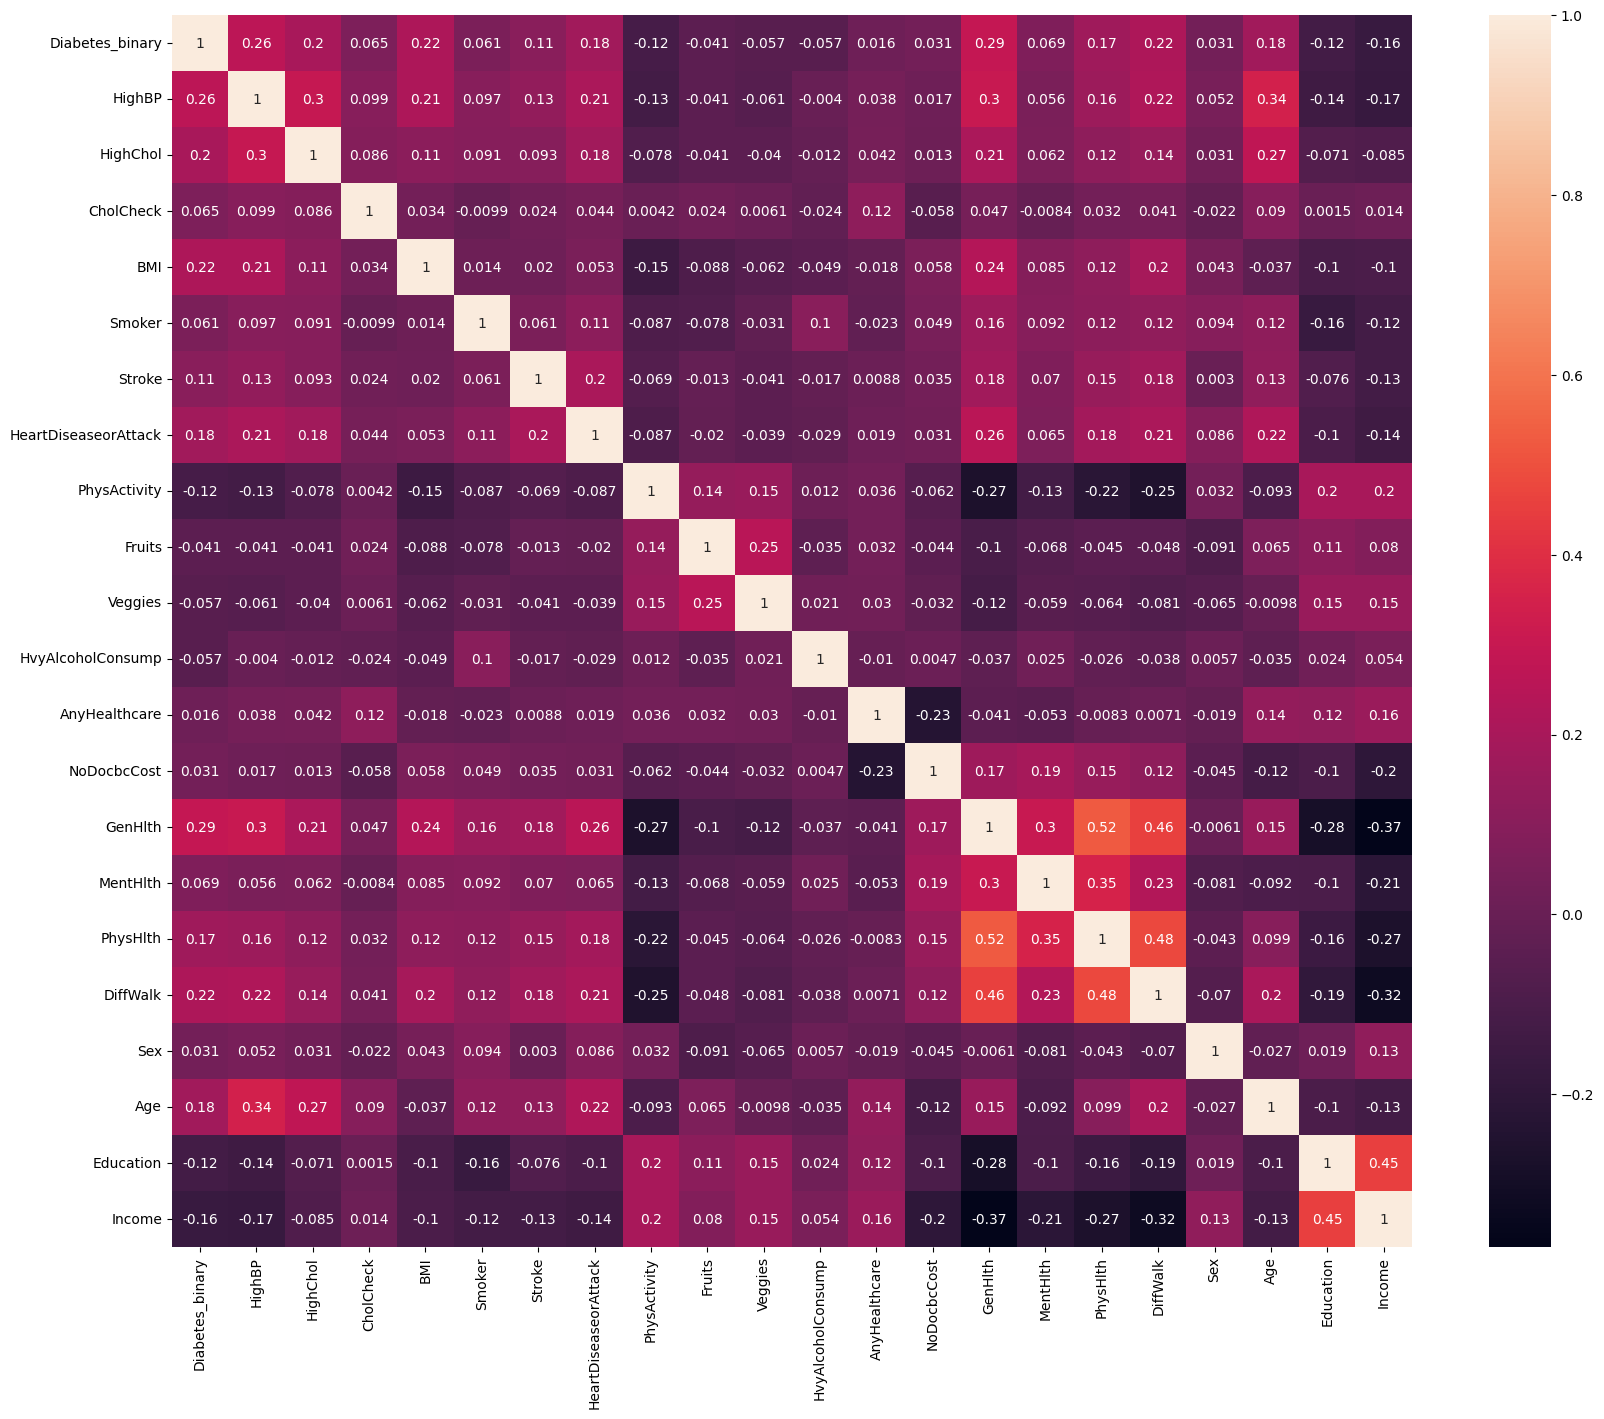

In [8]:
corr = df.corr()
plt.figure(figsize=(20,16))
sns.heatmap(corr , annot = True)

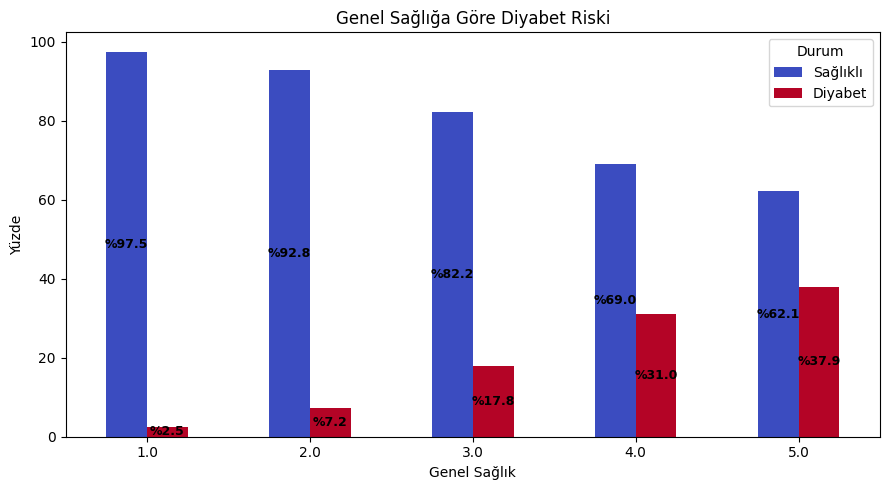

In [9]:
gh = pd.crosstab(df["GenHlth"], df["Diabetes_binary"], normalize="index") * 100

ax = gh.plot(kind="bar", figsize=(9, 5), colormap="coolwarm")
plt.title("Genel Sağlığa Göre Diyabet Riski")
plt.xlabel("Genel Sağlık")
plt.ylabel("Yüzde")
plt.legend(title="Durum", labels=["Sağlıklı","Diyabet"])
plt.xticks(rotation=0)

for p in ax.patches:
    width, height = p.get_width(), p.get_height()
    if height > 1:
        x, y = p.get_xy() 
        ax.text(x + width/2, y + height/2, f'%{height:.1f}', ha="center", va="center", fontsize=9, color="black", fontweight="bold")

plt.tight_layout()
plt.show()

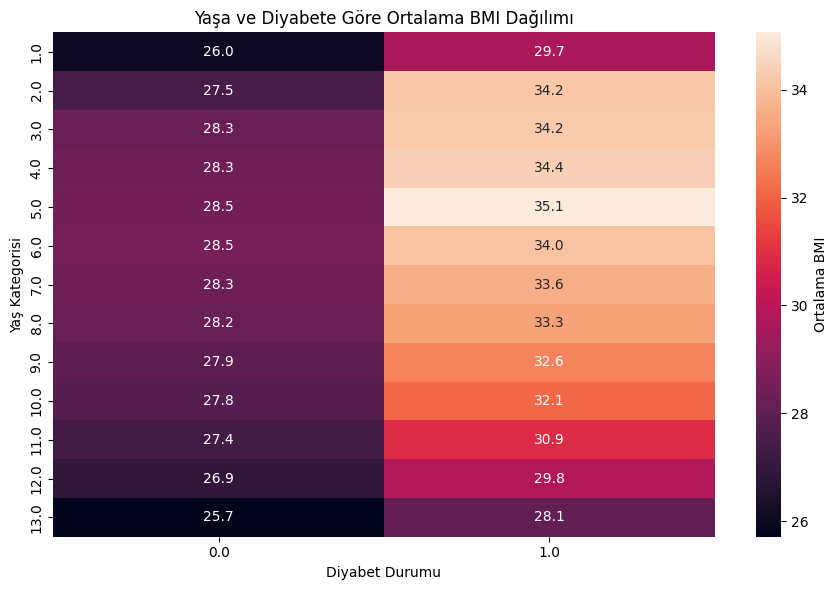

In [10]:
pivot_bmi = df.pivot_table(values="BMI", index="Age", columns="Diabetes_binary", aggfunc="mean")

plt.figure(figsize=(9, 6))
sns.heatmap(pivot_bmi, annot=True, fmt=".1f", cbar_kws={"label": "Ortalama BMI"})
plt.title("Yaşa ve Diyabete Göre Ortalama BMI Dağılımı")
plt.xlabel("Diyabet Durumu")
plt.ylabel("Yaş Kategorisi")
plt.tight_layout()
plt.show()

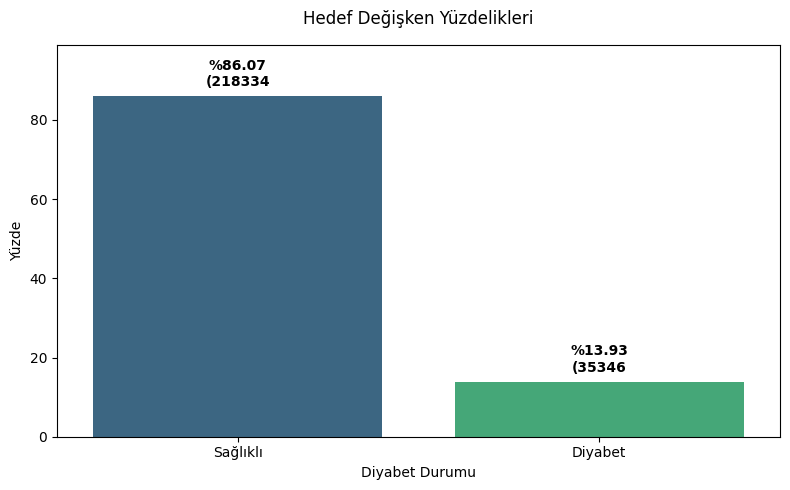

In [11]:
counts = df["Diabetes_binary"].value_counts().sort_index()
percentages = (df["Diabetes_binary"].value_counts(normalize=True).sort_index() * 100).round(2)

class_names = {0: "Sağlıklı", 1: "Diyabet"}

target_summary = pd.DataFrame({
    "Sınıf Tanımı": [class_names[i] for i in counts.index],"Hasta Sayısı": counts.values,"Yüzde": percentages.values}, 
                                index=counts.index)

plt.figure(figsize=(8, 5))
ax = sns.barplot(x=target_summary["Sınıf Tanımı"], y=target_summary["Yüzde"], palette="viridis")

for i, p in enumerate(ax.patches):
    count_val = target_summary["Hasta Sayısı"].iloc[i]
    pct_val = target_summary["Yüzde"].iloc[i]
    ax.annotate(f"%{pct_val:.2f}\n({count_val}",(p.get_x() + p.get_width() / 2., p.get_height()),
                ha="center", va="bottom", xytext=(0, 5),textcoords="offset points", fontsize=10, fontweight="bold")

plt.title("Hedef Değişken Yüzdelikleri", fontsize=12, pad=15)
plt.xlabel("Diyabet Durumu")
plt.ylabel("Yüzde")
plt.ylim(0, max(target_summary["Yüzde"]) * 1.15)
plt.tight_layout()
plt.show()

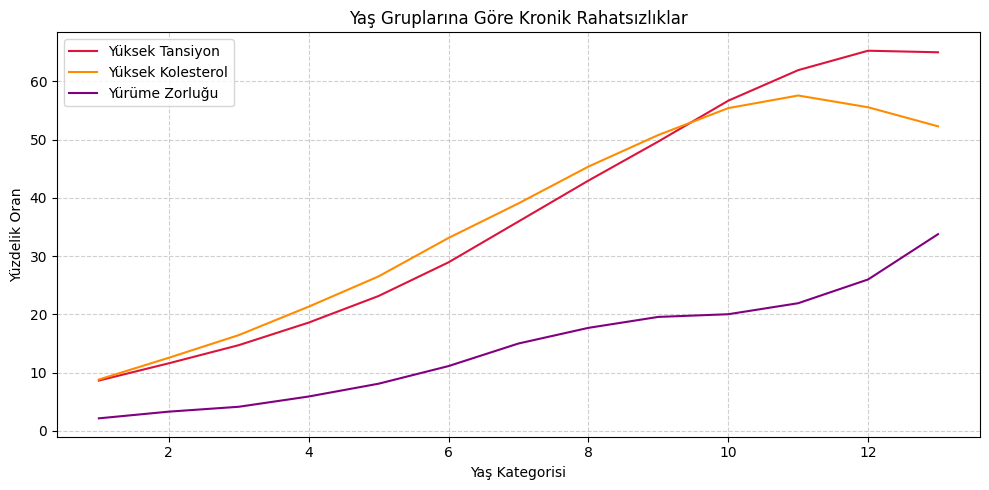

In [12]:
age_trends = df.groupby("Age")[["HighBP", "HighChol", "DiffWalk"]].mean() * 100

plt.figure(figsize=(10, 5))
plt.plot(age_trends.index, age_trends["HighBP"], label="Yüksek Tansiyon", color="crimson")
plt.plot(age_trends.index, age_trends["HighChol"], label="Yüksek Kolesterol", color="darkorange")
plt.plot(age_trends.index, age_trends["DiffWalk"], label="Yürüme Zorluğu", color="purple")

plt.title("Yaş Gruplarına Göre Kronik Rahatsızlıklar")
plt.xlabel("Yaş Kategorisi")
plt.ylabel("Yüzdelik Oran")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

# Outlier

IQR Analizi: 253680
"BMI" -> Alt Sınır: 13.5, Üst Sınır: 41.5
"BMI" -> IQR Outlier Satır Sayısı -->: 9,847 (%3.88)


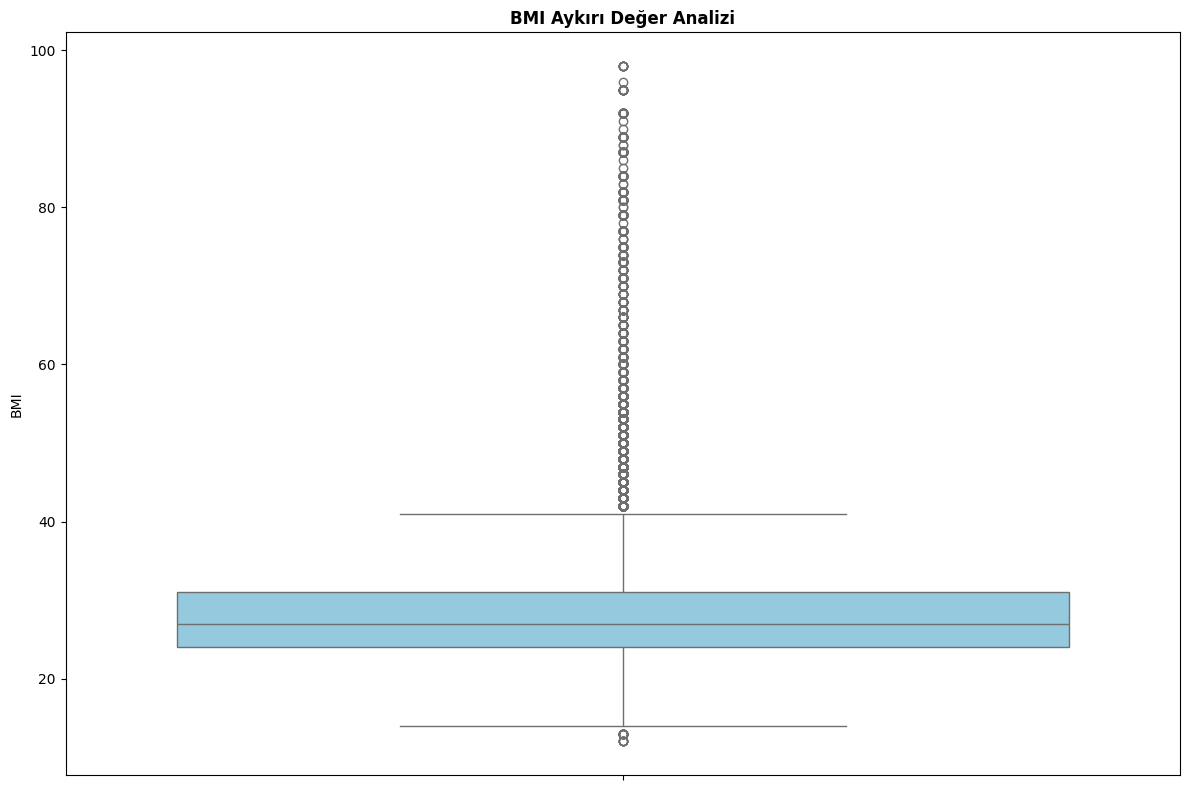

In [13]:
print(f"IQR Analizi: {len(df)}")
Q1 = df["BMI"].quantile(0.25)
Q3 = df["BMI"].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
outliers_iqr = df[(df["BMI"] < lower_bound) | (df["BMI"] > upper_bound)]
print(f'"{"BMI"}" -> Alt Sınır: {lower_bound:.1f}, Üst Sınır: {upper_bound:.1f}')
print(f'"{"BMI"}" -> IQR Outlier Satır Sayısı -->: {len(outliers_iqr):,} (%{len(outliers_iqr)/len(df)*100:.2f})')

plt.figure(figsize=(12, 8))
sns.boxplot(y=df["BMI"], color="skyblue")

plt.title("BMI Aykırı Değer Analizi", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

IQR Analizi Sonucu: 243833


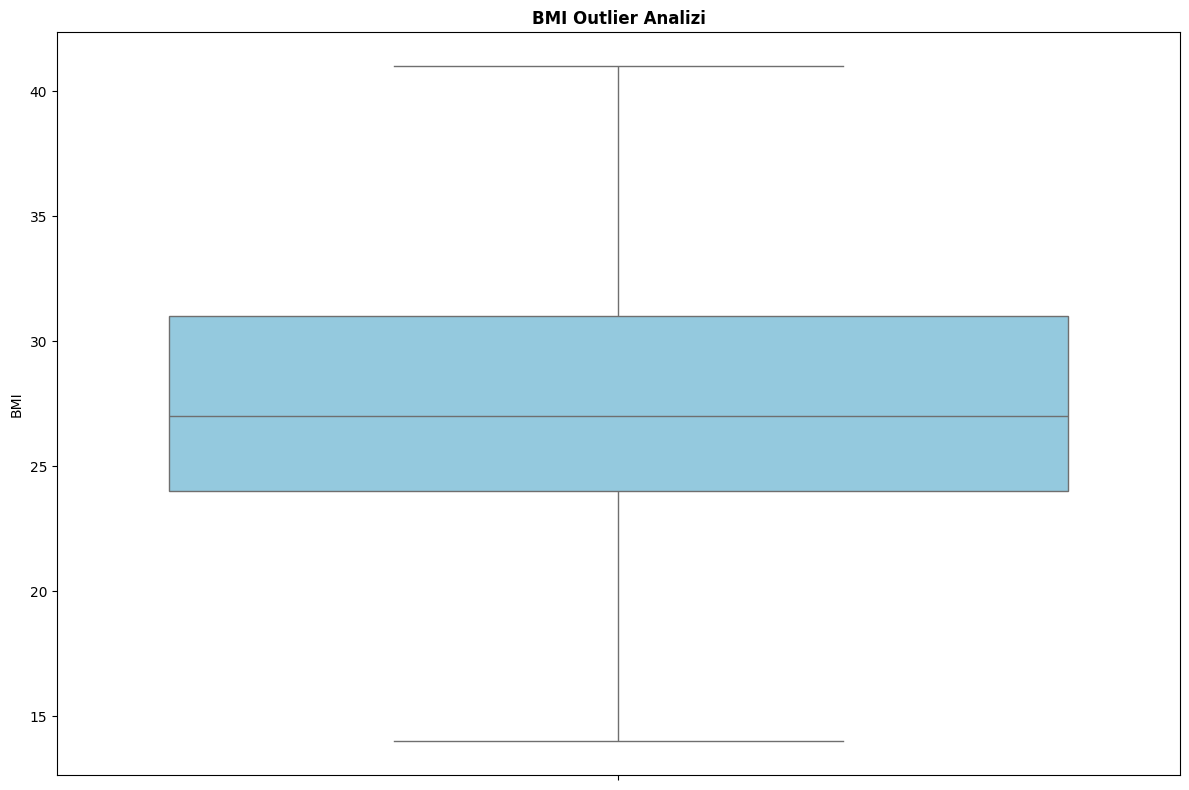

In [14]:
df = df[(df["BMI"] >= lower_bound) & (df["BMI"] <= upper_bound)].copy()
print(f"IQR Analizi Sonucu: {len(df)}")

plt.figure(figsize=(12, 8))
sns.boxplot(y=df["BMI"], color="skyblue")

plt.title("BMI Outlier Analizi", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

# Train Test Split

In [15]:
X = df.drop(columns=["Diabetes_binary"])
y = df["Diabetes_binary"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
sample_weights_train = compute_sample_weight(class_weight="balanced", y=y_train)

# Modelling

## XGB

Fitting 3 folds for each of 36 candidates, totalling 108 fits
En İyi Parametreler: {'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 250, 'scale_pos_weight': 7}
XGB Balanced Accuracy: 0.7513
XGB ROC-AUC Skoru: 0.8274
XGB CR:
              precision    recall  f1-score   support

    Sağlıklı       0.96      0.70      0.81     42371
       Hasta       0.29      0.81      0.42      6396

    accuracy                           0.71     48767
   macro avg       0.62      0.75      0.61     48767
weighted avg       0.87      0.71      0.76     48767



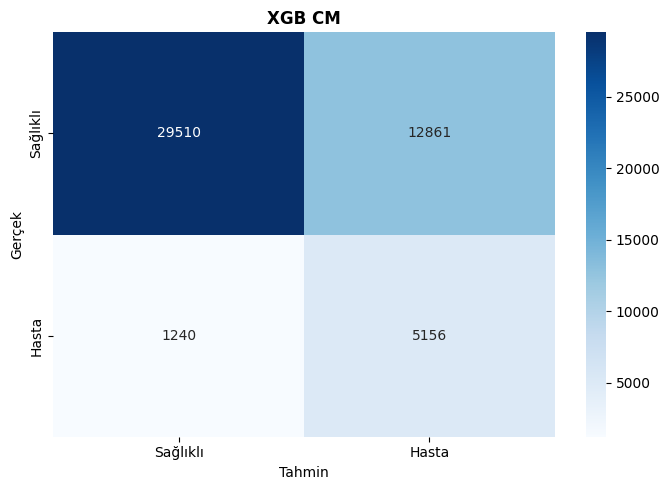

In [16]:
xgb_base = xgb.XGBClassifier(
    objective="binary:logistic",
    eval_metric="auc",
    random_state=42,
    n_jobs=-1
)

param_grid = {
    "n_estimators": [230 , 250 , 260],
    "max_depth": [ 3,5,7],
    "learning_rate": [0.05, 0.1],
    "scale_pos_weight": [7,10]
}

grid_search_xgb = GridSearchCV(
    estimator=xgb_base,
    param_grid=param_grid,
    cv=3,
    scoring="balanced_accuracy",
    verbose=1,
    n_jobs=-1
)

grid_search_xgb.fit(X_train, y_train)

print(f"En İyi Parametreler: {grid_search_xgb.best_params_}")
best_xgb = grid_search_xgb.best_estimator_
y_pred_xgb = best_xgb.predict(X_test)
y_pred_proba_xgb = best_xgb.predict_proba(X_test)[:, 1]

bal_acc = balanced_accuracy_score(y_test, y_pred_xgb)
roc_auc = roc_auc_score(y_test, y_pred_proba_xgb)

print(f"XGB Balanced Accuracy: {bal_acc:.4f}")
print(f"XGB ROC-AUC Skoru: {roc_auc:.4f}")
print("XGB CR:")
print(classification_report(y_test, y_pred_xgb, target_names=["Sağlıklı", "Hasta"]))

cm = confusion_matrix(y_test, y_pred_xgb)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",xticklabels=["Sağlıklı", "Hasta"],yticklabels=["Sağlıklı", "Hasta"])
plt.title("XGB CM", fontsize=12, fontweight="bold")
plt.xlabel("Tahmin")
plt.ylabel("Gerçek")
plt.tight_layout()
plt.show()

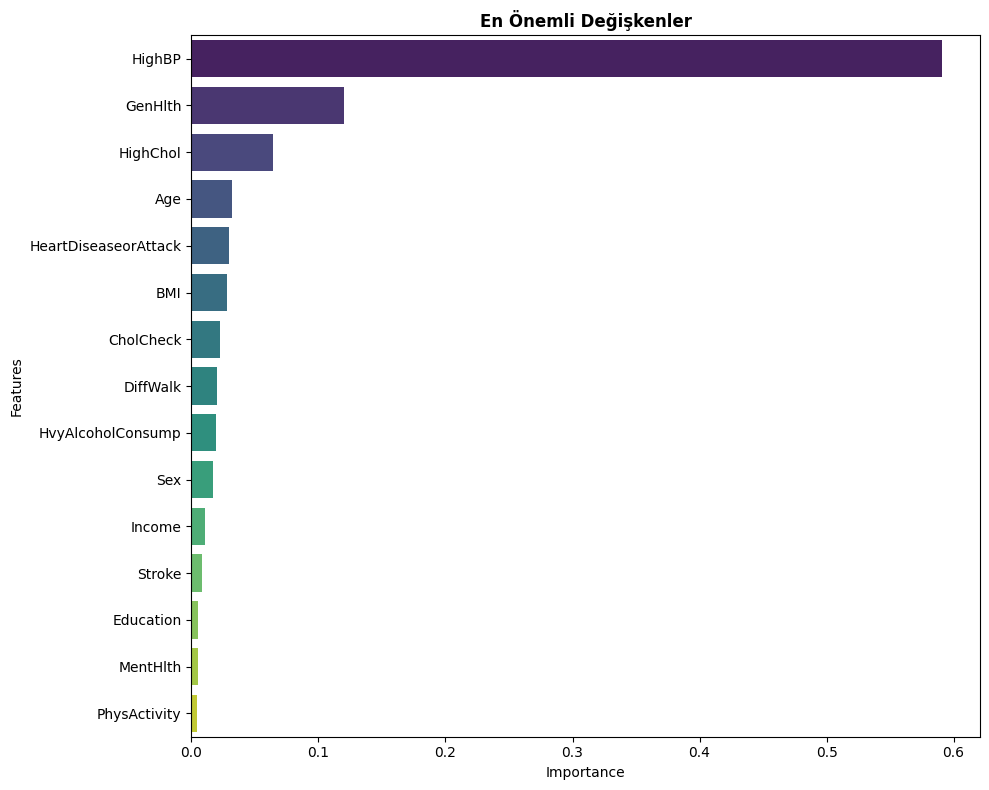

In [17]:
feature_importances = best_xgb.feature_importances_

feature_importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": feature_importances
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 8))
sns.barplot(x='Importance',y='Feature',data=feature_importance_df.head(15),palette="viridis")
plt.title("En Önemli Değişkenler", fontsize=12, fontweight="bold")
plt.xlabel("Importance")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

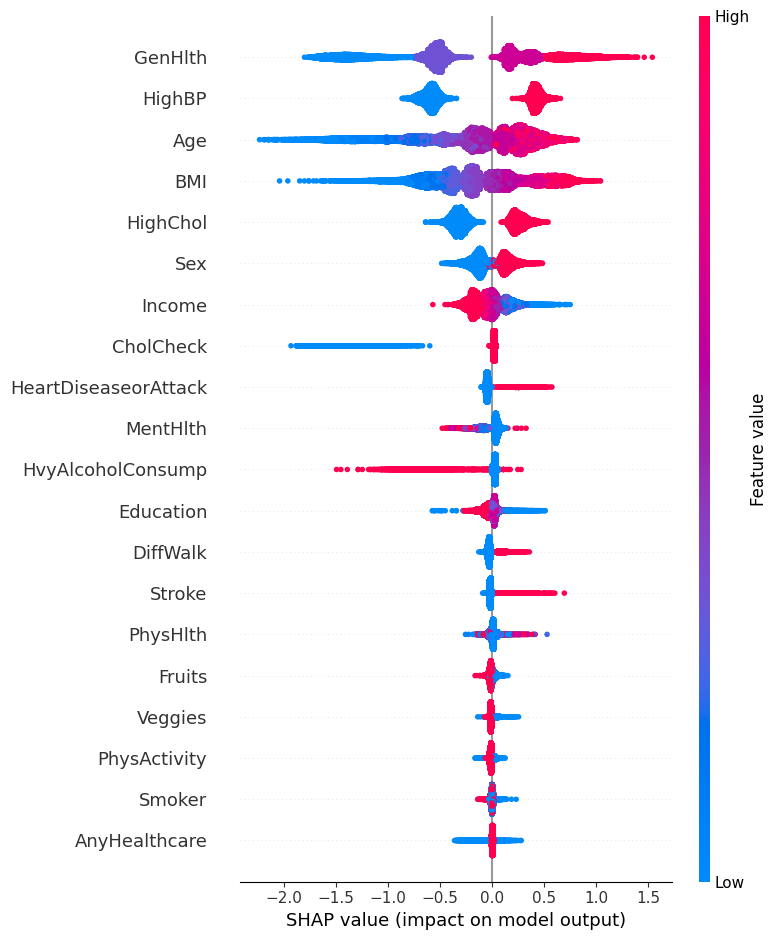

In [18]:
explainer = shap.TreeExplainer(best_xgb)

shap_values = explainer.shap_values(X_test)

plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values, X_test, plot_type="dot")
plt.show()

## RF

Fitting 3 folds for each of 15 candidates, totalling 45 fits
En İyi Parametreler:: {'n_estimators': 100, 'min_samples_split': 10, 'min_samples_leaf': 4, 'max_depth': 10}
RF Balanced Accuracy : 0.7472
RF ROC-AUC Skoru   : 0.8237
RF CR
              precision    recall  f1-score   support

    Sağlıklı       0.95      0.72      0.82     42371
       Hasta       0.30      0.77      0.43      6396

    accuracy                           0.73     48767
   macro avg       0.63      0.75      0.62     48767
weighted avg       0.87      0.73      0.77     48767



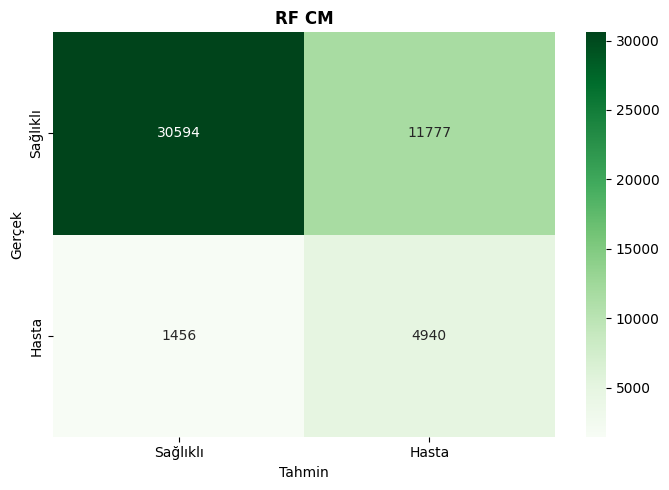

In [19]:
rf_base = RandomForestClassifier(
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

param_distributions = {
    "n_estimators": [100, 200, 300, 400],
    "max_depth": [8, 10, 15, 20, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4]
}

random_search_rf = RandomizedSearchCV(
    estimator=rf_base,
    param_distributions=param_distributions,
    n_iter=15,          
    cv=3,
    scoring="balanced_accuracy",
    random_state=42,
    verbose=1,
    n_jobs=-1
)

random_search_rf.fit(X_train, y_train)

print(f"En İyi Parametreler:: {random_search_rf.best_params_}")

best_rf = random_search_rf.best_estimator_
y_pred_rf = best_rf.predict(X_test)
y_pred_proba_rf = best_rf.predict_proba(X_test)[:, 1]

bal_acc = balanced_accuracy_score(y_test, y_pred_rf)
roc_auc = roc_auc_score(y_test, y_pred_proba_rf)

print(f"RF Balanced Accuracy : {bal_acc:.4f}")
print(f"RF ROC-AUC Skoru   : {roc_auc:.4f}")

print("RF CR")
print(classification_report(y_test, y_pred_rf, target_names=["Sağlıklı", "Hasta"]))

cm = confusion_matrix(y_test, y_pred_rf)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens",xticklabels=["Sağlıklı", "Hasta"],yticklabels=["Sağlıklı", "Hasta"])
plt.title("RF CM", fontsize=12, fontweight="bold")
plt.xlabel("Tahmin")
plt.ylabel("Gerçek")
plt.tight_layout()
plt.show()

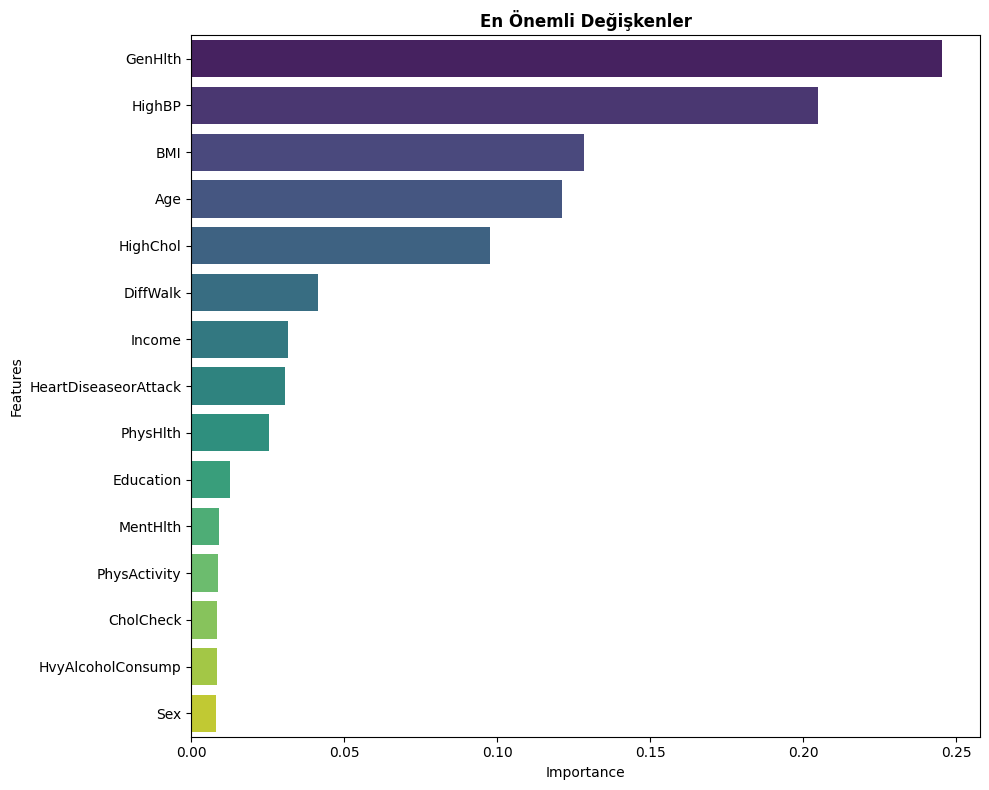

In [20]:
feature_importances = best_rf.feature_importances_

feature_importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": feature_importances
}).sort_values(by="Importance", ascending=False)

plt.figure(figsize=(10, 8))
sns.barplot(x="Importance",y="Feature",data=feature_importance_df.head(15),palette="viridis")
plt.title("En Önemli Değişkenler", fontsize=12, fontweight="bold")
plt.xlabel("Importance")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

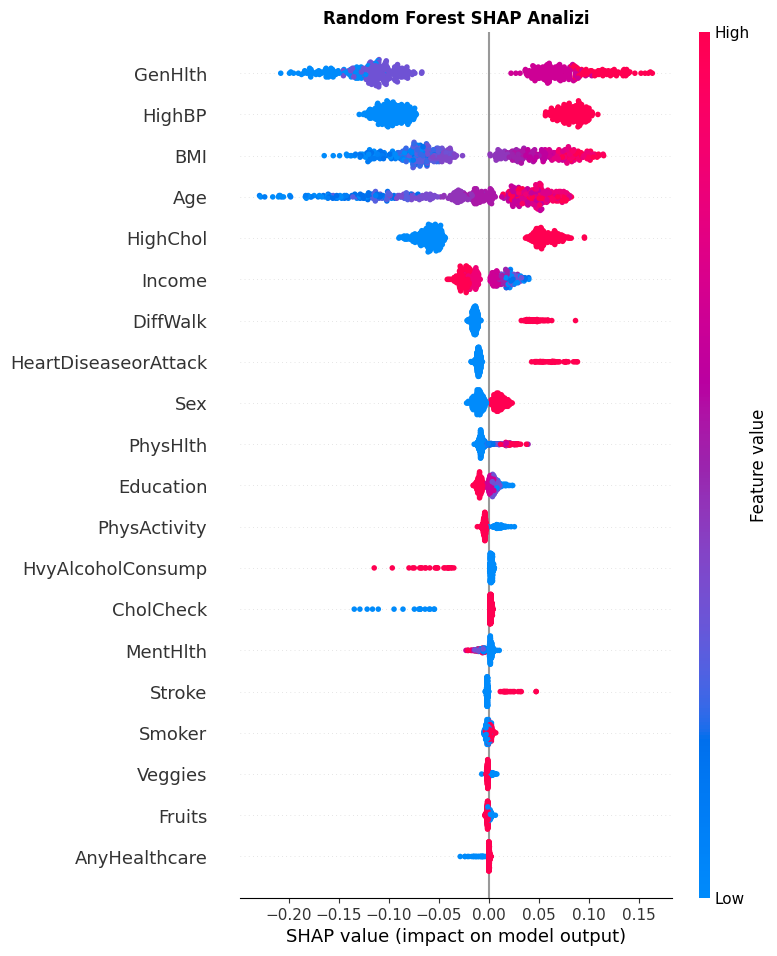

In [21]:
test_sample = X_test.sample(500, random_state=42)

explainer_rf = shap.TreeExplainer(best_rf)
shap_values_rf = explainer_rf.shap_values(test_sample)

if isinstance(shap_values_rf, list):
    shap_vals_rf_plot = shap_values_rf[1] 
elif len(shap_values_rf.shape) == 3:
    shap_vals_rf_plot = shap_values_rf[:, :, 1]
else:
    shap_vals_rf_plot = shap_values_rf

plt.close("all") 
plt.figure(figsize=(10, 8))

shap.summary_plot(shap_vals_rf_plot, test_sample, plot_type="dot", show=False)

plt.title("Random Forest SHAP Analizi", fontsize=12, fontweight="bold")
plt.show()

## ADA

Fitting 3 folds for each of 10 candidates, totalling 30 fits
En İyi Parametreler: {'n_estimators': 200, 'learning_rate': 0.5}
AdaBoost Balanced Accuracy : 0.7455
AdaBoost ROC-AUC Skoru   : 0.8211
AdaBoost CR
              precision    recall  f1-score   support

    Sağlıklı       0.95      0.72      0.82     42371
       Hasta       0.29      0.77      0.42      6396

    accuracy                           0.72     48767
   macro avg       0.62      0.75      0.62     48767
weighted avg       0.87      0.72      0.77     48767



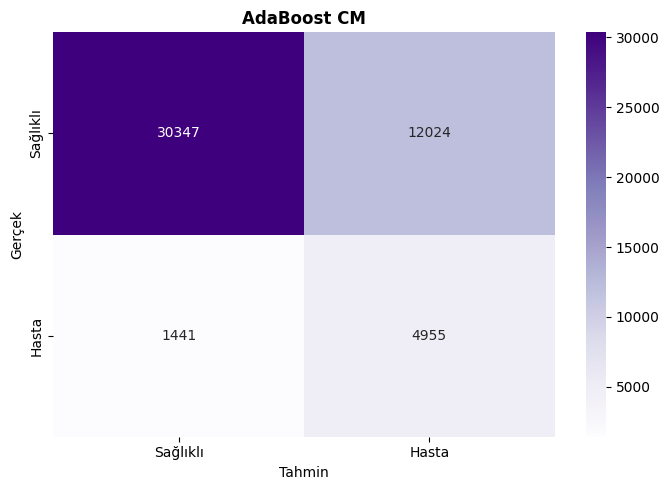

In [22]:
ada_base = AdaBoostClassifier(
    random_state=42
)
param_distributions_ada = {
    "n_estimators": [50, 100, 150, 200, 300],
    "learning_rate": [0.01, 0.05, 0.1, 0.2, 0.5]
}

random_search_ada = RandomizedSearchCV(
    estimator=ada_base,
    param_distributions=param_distributions_ada,
    n_iter=10,          
    cv=3,
    scoring="balanced_accuracy",
    random_state=42,
    verbose=1,
    n_jobs=-1
)

random_search_ada.fit(X_train, y_train, sample_weight=sample_weights_train)

print(f"En İyi Parametreler: {random_search_ada.best_params_}")
best_ada = random_search_ada.best_estimator_
y_pred_ada = best_ada.predict(X_test)
y_pred_proba_ada = best_ada.predict_proba(X_test)[:, 1]

bal_acc = balanced_accuracy_score(y_test, y_pred_ada)
roc_auc = roc_auc_score(y_test, y_pred_proba_ada)

print(f"AdaBoost Balanced Accuracy : {bal_acc:.4f}")
print(f"AdaBoost ROC-AUC Skoru   : {roc_auc:.4f}")
print("AdaBoost CR")
print(classification_report(y_test, y_pred_ada, target_names=["Sağlıklı", "Hasta"]))

cm = confusion_matrix(y_test, y_pred_ada)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Purples",
            xticklabels=["Sağlıklı", "Hasta"],
            yticklabels=["Sağlıklı", "Hasta"])
plt.title("AdaBoost CM", fontsize=12, fontweight="bold")
plt.xlabel("Tahmin")
plt.ylabel("Gerçek")
plt.tight_layout()
plt.show()

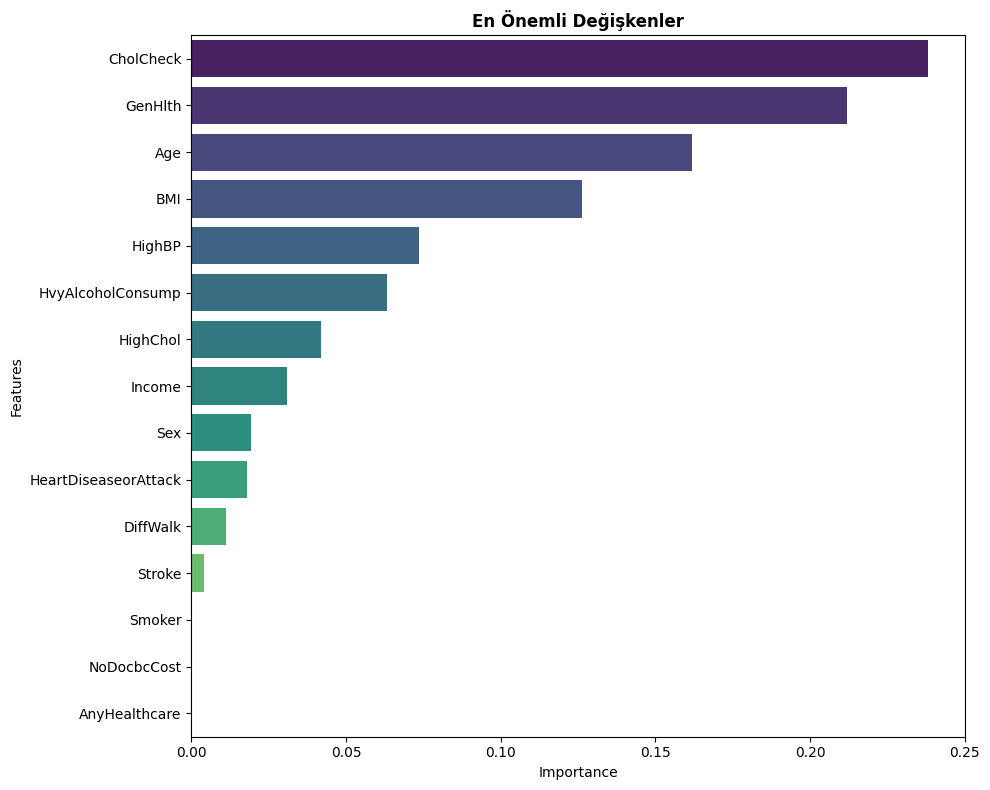

In [23]:
feature_importances = best_ada.feature_importances_

feature_importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": feature_importances
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 8))
sns.barplot(x='Importance',y='Feature',data=feature_importance_df.head(15),palette='viridis')
plt.title("En Önemli Değişkenler", fontsize=12, fontweight="bold")
plt.xlabel("Importance")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

## LightGBM

[LightGBM] [Info] Number of positive: 25583, number of negative: 169483
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.027033 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 155
[LightGBM] [Info] Number of data points in the train set: 195066, number of used features: 21
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000
LGB Balanced Accuracy: 0.7509
LGB ROC-AUC Skoru: 0.8268
LGB CR:
              precision    recall  f1-score   support

    Sağlıklı       0.96      0.70      0.81     42371
       Hasta       0.29      0.80      0.42      6396

    accuracy                           0.72     48767
   macro avg       0.62      0.75      0.62     48767
weighted avg       0.87      0.72      0.76     48767



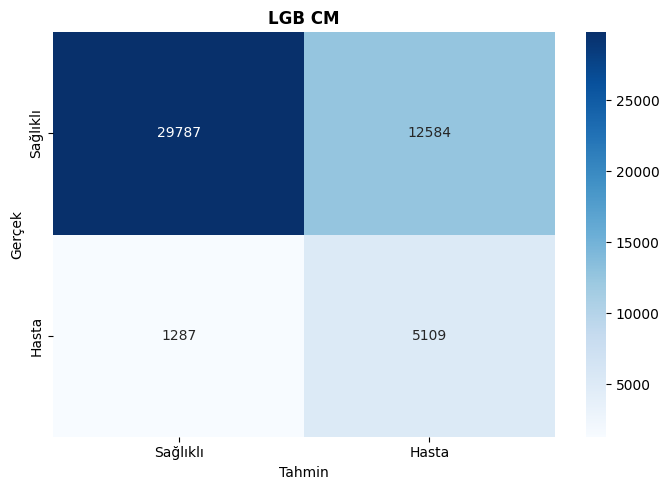

In [24]:
lgb_model = lgb.LGBMClassifier(
    random_state=42,
    n_estimators=100,
    learning_rate=0.05,
    class_weight="balanced" 
)

lgb_model.fit(X_train, y_train)

lgb_pred = lgb_model.predict(X_test)
lgb_proba = lgb_model.predict_proba(X_test)[:, 1]

bal_acc = balanced_accuracy_score(y_test, lgb_pred)
roc_auc = roc_auc_score(y_test, lgb_proba)

print(f"LGB Balanced Accuracy: {bal_acc:.4f}")
print(f"LGB ROC-AUC Skoru: {roc_auc:.4f}")
print("LGB CR:")
print(classification_report(y_test, lgb_pred, target_names=["Sağlıklı", "Hasta"]))

cm = confusion_matrix(y_test, lgb_pred)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",xticklabels=["Sağlıklı", "Hasta"],yticklabels=["Sağlıklı", "Hasta"])
plt.title("LGB CM", fontsize=12, fontweight="bold")
plt.xlabel("Tahmin")
plt.ylabel("Gerçek")
plt.tight_layout()
plt.show()

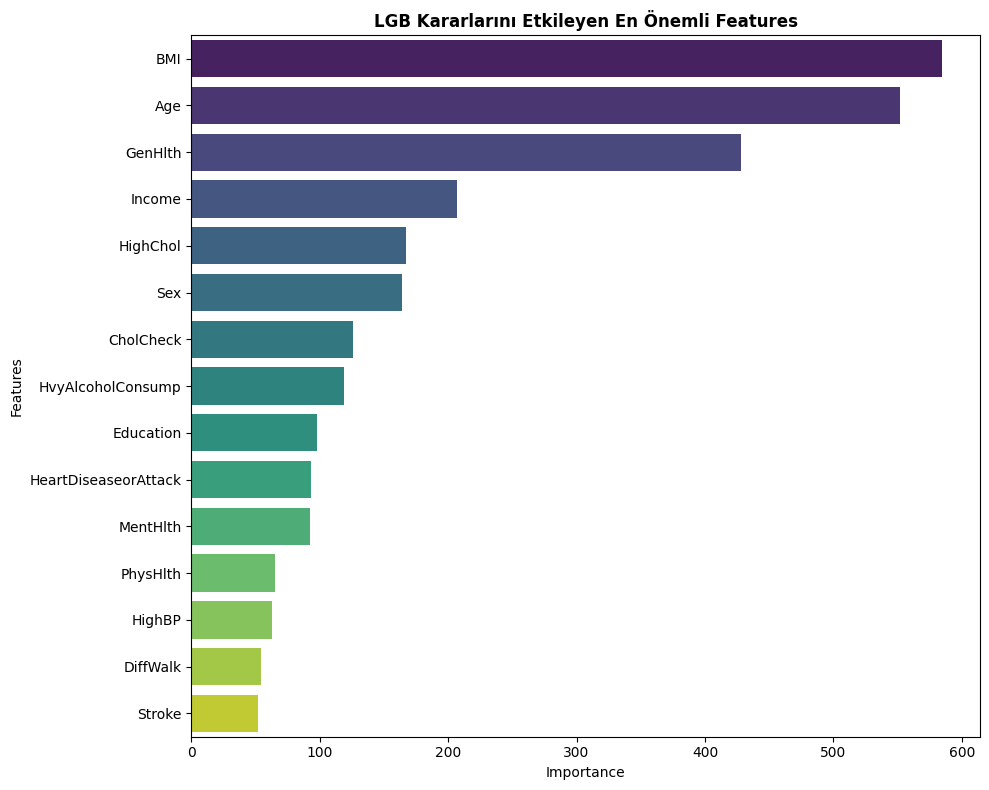

In [25]:
target_model = lgb_model

feature_importances = target_model.feature_importances_

feature_importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": feature_importances
}).sort_values(by='Importance', ascending=False)

plt.close("all")
plt.figure(figsize=(10, 8))
sns.barplot(x="Importance", y="Feature", data=feature_importance_df.head(15), palette="viridis")
plt.title("LGB Kararlarını Etkileyen En Önemli Features", fontsize=12, fontweight="bold")
plt.xlabel("Importance", fontsize=10)
plt.ylabel("Features", fontsize=10)
plt.tight_layout()
plt.show()

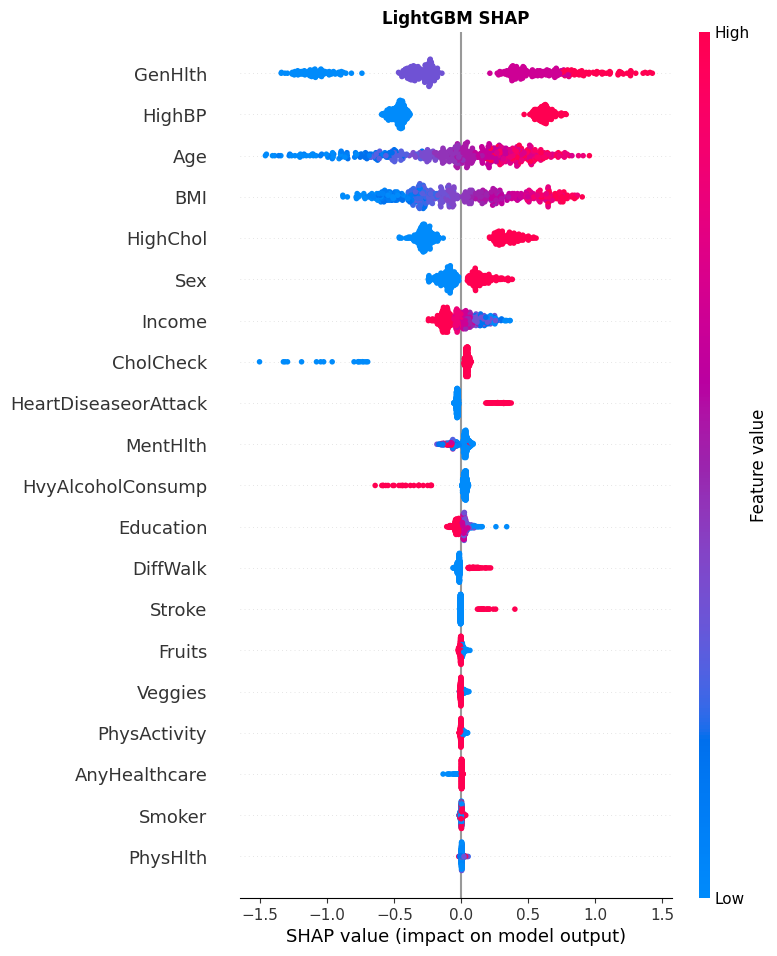

In [26]:
test_sample_lgb = X_test.sample(500, random_state=42)

explainer_lgb = shap.TreeExplainer(lgb_model)
shap_values_lgb = explainer_lgb.shap_values(test_sample_lgb)

if isinstance(shap_values_lgb, list):
    shap_vals_lgb_plot = shap_values_lgb[1]
elif len(shap_values_lgb.shape) == 3:
    shap_vals_lgb_plot = shap_values_lgb[:, :, 1]
else:
    shap_vals_lgb_plot = shap_values_lgb

plt.close("all") 
plt.figure(figsize=(10, 8))

shap.summary_plot(shap_vals_lgb_plot, test_sample_lgb, plot_type="dot", show=False)

plt.title("LightGBM SHAP", fontsize=12, fontweight="bold")
plt.show()

## CatBoosting

Cat Balanced Accuracy: 0.7524
Cat ROC-AUC Skoru: 0.8277
Cat CR:
              precision    recall  f1-score   support

    Sağlıklı       0.96      0.71      0.81     42371
       Hasta       0.29      0.80      0.43      6396

    accuracy                           0.72     48767
   macro avg       0.62      0.75      0.62     48767
weighted avg       0.87      0.72      0.76     48767



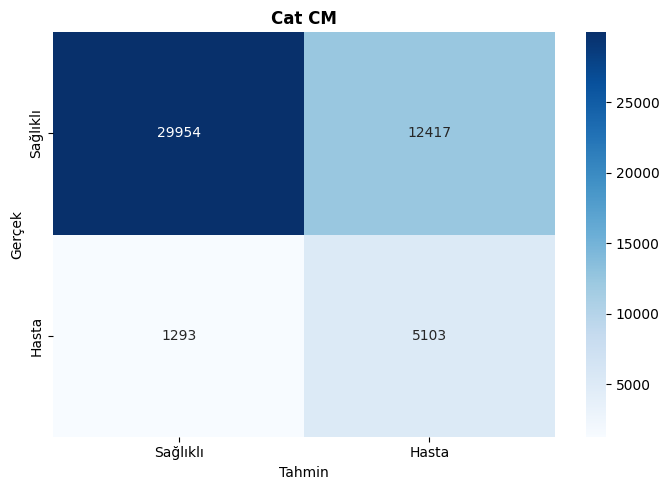

In [27]:
cat_model = CatBoostClassifier(
    random_state=42,
    iterations=300,
    learning_rate=0.05,
    auto_class_weights="Balanced", 
    verbose=0 
)

cat_model.fit(X_train, y_train)

cat_pred = cat_model.predict(X_test)
cat_proba = cat_model.predict_proba(X_test)[:, 1]

bal_acc = balanced_accuracy_score(y_test, cat_pred)
roc_auc = roc_auc_score(y_test, cat_proba)

print(f"Cat Balanced Accuracy: {bal_acc:.4f}")
print(f"Cat ROC-AUC Skoru: {roc_auc:.4f}")
print("Cat CR:")
print(classification_report(y_test, cat_pred, target_names=["Sağlıklı", "Hasta"]))

cm = confusion_matrix(y_test, cat_pred)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",xticklabels=["Sağlıklı", "Hasta"],yticklabels=["Sağlıklı", "Hasta"])
plt.title("Cat CM", fontsize=12, fontweight="bold")
plt.xlabel("Tahmin")
plt.ylabel("Gerçek")
plt.tight_layout()
plt.show()

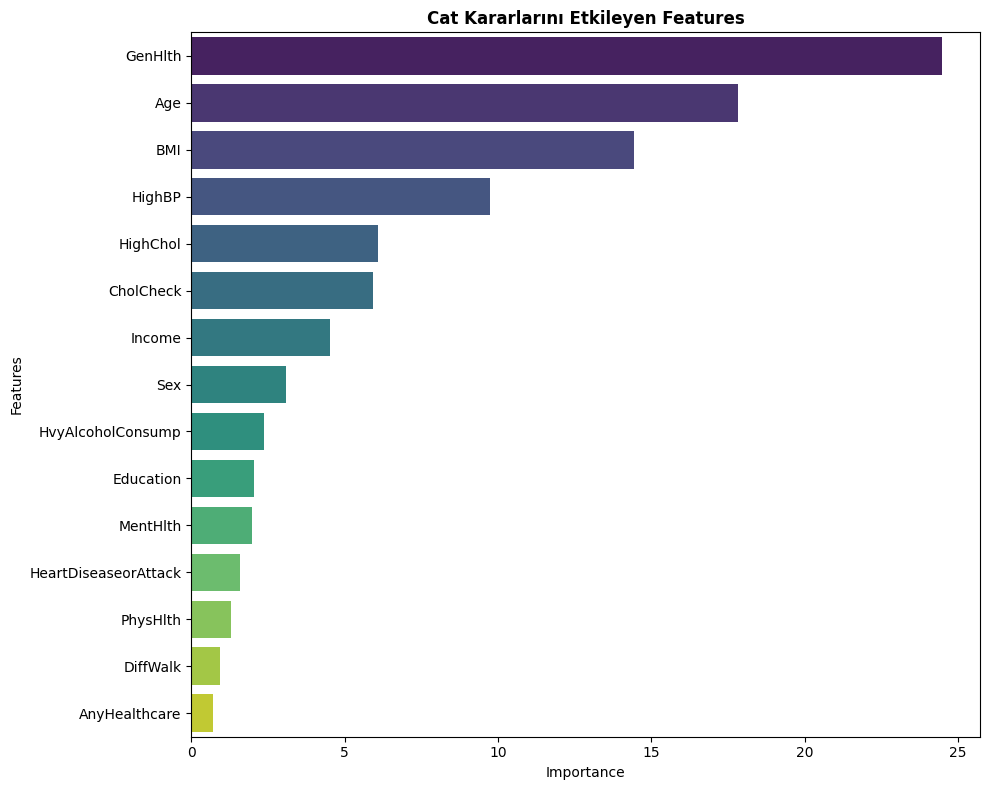

In [28]:
target_model = cat_model

feature_importances = target_model.feature_importances_

feature_importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": feature_importances}).sort_values(by="Importance", ascending=False)

plt.close("all")
plt.figure(figsize=(10, 8))
sns.barplot(x="Importance", y="Feature", data=feature_importance_df.head(15), palette="viridis")
plt.title("Cat Kararlarını Etkileyen Features", fontsize=12, fontweight="bold")
plt.xlabel("Importance", fontsize=10)
plt.ylabel("Features", fontsize=10)
plt.tight_layout()
plt.show()

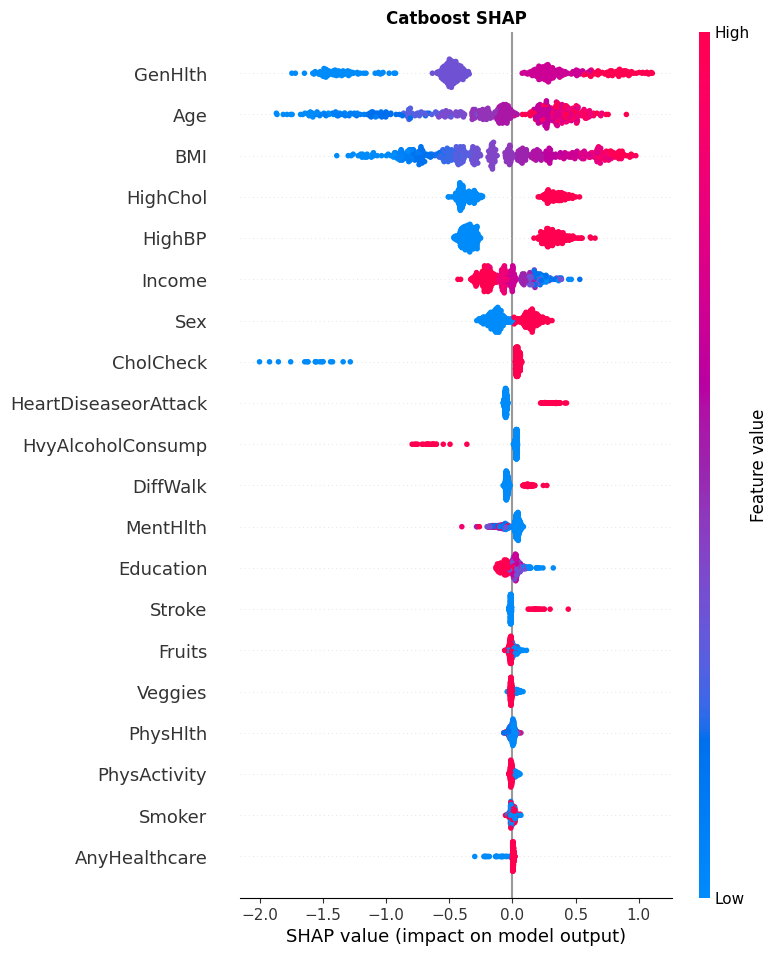

In [29]:
test_sample_cat = X_test.sample(500, random_state=42)

explainer_cat = shap.TreeExplainer(cat_model)
shap_values_cat = explainer_cat.shap_values(test_sample_cat)

if isinstance(shap_values_cat, list):
    shap_vals_cat_plot = shap_values_cat[1]
elif len(shap_values_cat.shape) == 3:
    shap_vals_cat_plot = shap_values_cat[:, :, 1]
else:
    shap_vals_cat_plot = shap_values_cat

plt.close("all") 
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_vals_cat_plot, test_sample_cat, plot_type="dot", show=False)
plt.title("Catboost SHAP", fontsize=12, fontweight="bold")
plt.show()

## Ensemble

[LightGBM] [Info] Number of positive: 25583, number of negative: 169483
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.022084 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 155
[LightGBM] [Info] Number of data points in the train set: 195066, number of used features: 21
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000
ENS Balanced Accuracy: 0.7523
ENS ROC-AUC Skoru: 0.8278
ENS CR:
              precision    recall  f1-score   support

    Sağlıklı       0.96      0.70      0.81     42371
       Hasta       0.29      0.80      0.43      6396

    accuracy                           0.72     48767
   macro avg       0.62      0.75      0.62     48767
weighted avg       0.87      0.72      0.76     48767



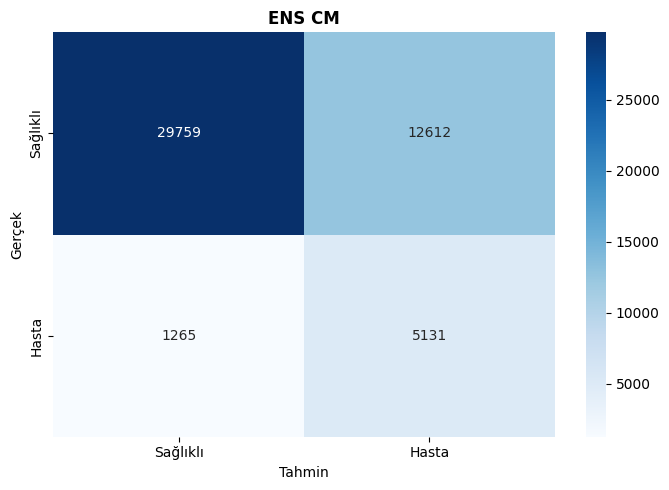

In [30]:
ensemble_model = VotingClassifier(
    estimators=[
        ("xgb", best_xgb),
        ("lgb", lgb_model),
        ("cat", cat_model)
    ],
    voting="soft"
)

ensemble_model.fit(X_train, y_train)

ensemble_pred = ensemble_model.predict(X_test)
ensemble_proba = ensemble_model.predict_proba(X_test)[:, 1]

bal_acc = balanced_accuracy_score(y_test, ensemble_pred)
roc_auc = roc_auc_score(y_test, ensemble_proba)

print(f"ENS Balanced Accuracy: {bal_acc:.4f}")
print(f"ENS ROC-AUC Skoru: {roc_auc:.4f}")
print("ENS CR:")
print(classification_report(y_test, ensemble_pred, target_names=["Sağlıklı", "Hasta"]))

cm = confusion_matrix(y_test, ensemble_pred)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",xticklabels=["Sağlıklı", "Hasta"],yticklabels=["Sağlıklı", "Hasta"])
plt.title("ENS CM", fontsize=12, fontweight="bold")
plt.xlabel("Tahmin")
plt.ylabel("Gerçek")
plt.tight_layout()
plt.show()

## Tabnet

epoch 0  | loss: 0.52791 | val_0_auc: 0.82193 |  0:00:20s
epoch 1  | loss: 0.51463 | val_0_auc: 0.82419 |  0:00:41s
epoch 2  | loss: 0.51263 | val_0_auc: 0.82266 |  0:01:01s
epoch 3  | loss: 0.5119  | val_0_auc: 0.82429 |  0:01:21s
epoch 4  | loss: 0.50986 | val_0_auc: 0.82271 |  0:01:41s
epoch 5  | loss: 0.5097  | val_0_auc: 0.8229  |  0:02:01s
epoch 6  | loss: 0.50946 | val_0_auc: 0.82488 |  0:02:20s
epoch 7  | loss: 0.50738 | val_0_auc: 0.8257  |  0:02:40s
epoch 8  | loss: 0.50625 | val_0_auc: 0.82403 |  0:03:00s
epoch 9  | loss: 0.50681 | val_0_auc: 0.8252  |  0:03:20s
epoch 10 | loss: 0.50754 | val_0_auc: 0.82492 |  0:03:39s
epoch 11 | loss: 0.50526 | val_0_auc: 0.82428 |  0:03:59s
epoch 12 | loss: 0.50665 | val_0_auc: 0.82424 |  0:04:19s

Early stopping occurred at epoch 12 with best_epoch = 7 and best_val_0_auc = 0.8257
Tabnet Balanced Accuracy: 0.7504
Tabnet ROC-AUC Skoru: 0.8257
Tabnet CR:
              precision    recall  f1-score   support

    Sağlıklı       0.96      0.69

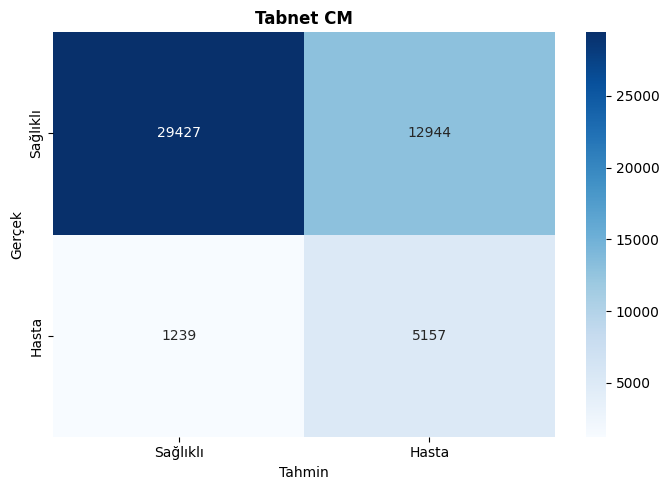

In [31]:
tabnet_model = TabNetClassifier(
    optimizer_fn=torch.optim.Adam,
    optimizer_params=dict(lr=2e-2),
    mask_type="entmax", 
    seed=42
)

X_train_np = X_train.to_numpy()
y_train_np = y_train.to_numpy()
X_test_np = X_test.to_numpy()
y_test_np = y_test.to_numpy()

tabnet_model.fit(
    X_train_np, y_train_np,
    eval_set=[(X_test_np, y_test_np)],
    eval_metric=["auc"],
    max_epochs=20,
    batch_size=256,
    virtual_batch_size=128,
    patience=5,
    weights=1 
)

tabnet_pred = tabnet_model.predict(X_test_np)
tabnet_proba = tabnet_model.predict_proba(X_test_np)[:, 1]

bal_acc = balanced_accuracy_score(y_test, tabnet_pred)
roc_auc = roc_auc_score(y_test, tabnet_proba)

print(f"Tabnet Balanced Accuracy: {bal_acc:.4f}")
print(f"Tabnet ROC-AUC Skoru: {roc_auc:.4f}")
print("Tabnet CR:")
print(classification_report(y_test, tabnet_pred, target_names=["Sağlıklı", "Hasta"]))

cm = confusion_matrix(y_test, tabnet_pred)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",xticklabels=["Sağlıklı", "Hasta"],yticklabels=["Sağlıklı", "Hasta"])
plt.title("Tabnet CM", fontsize=12, fontweight="bold")
plt.xlabel("Tahmin")
plt.ylabel("Gerçek")
plt.tight_layout()
plt.show()

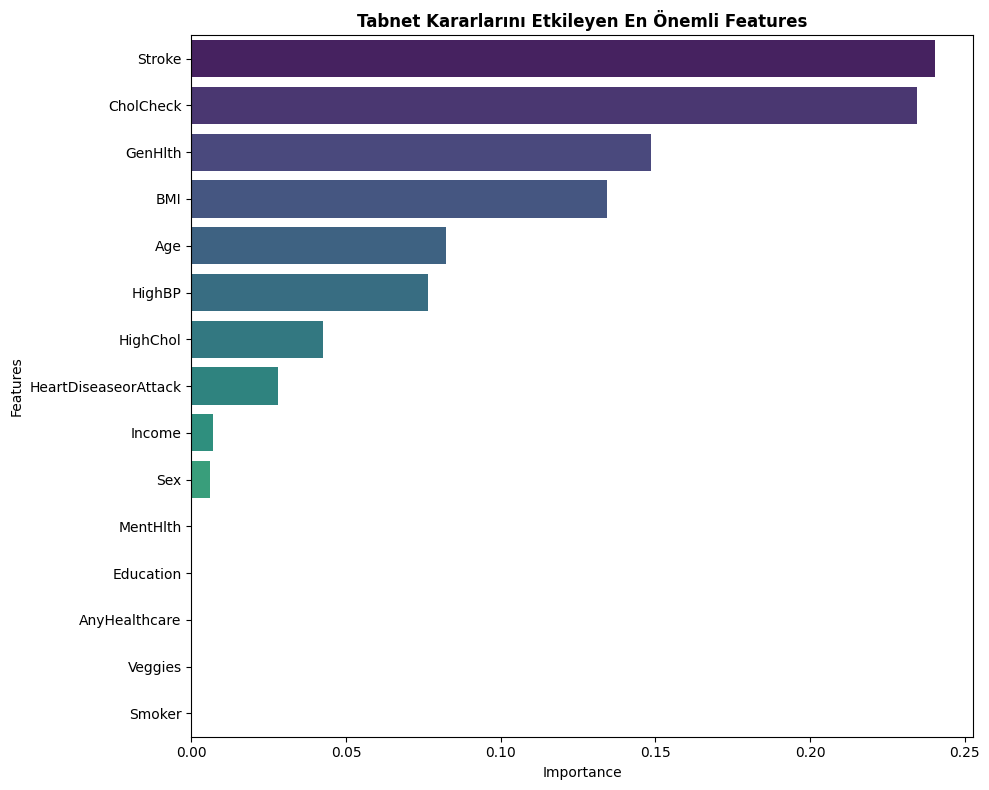

In [32]:
target_model = tabnet_model 

feature_importances = target_model.feature_importances_

feature_importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": feature_importances
}).sort_values(by='Importance', ascending=False)

plt.close("all")
plt.figure(figsize=(10, 8))
sns.barplot(x="Importance", y="Feature", data=feature_importance_df.head(15), palette="viridis")
plt.title("Tabnet Kararlarını Etkileyen En Önemli Features", fontsize=12, fontweight="bold")
plt.xlabel("Importance", fontsize=10)
plt.ylabel("Features", fontsize=10)
plt.tight_layout()
plt.show()

# Final Evaluation

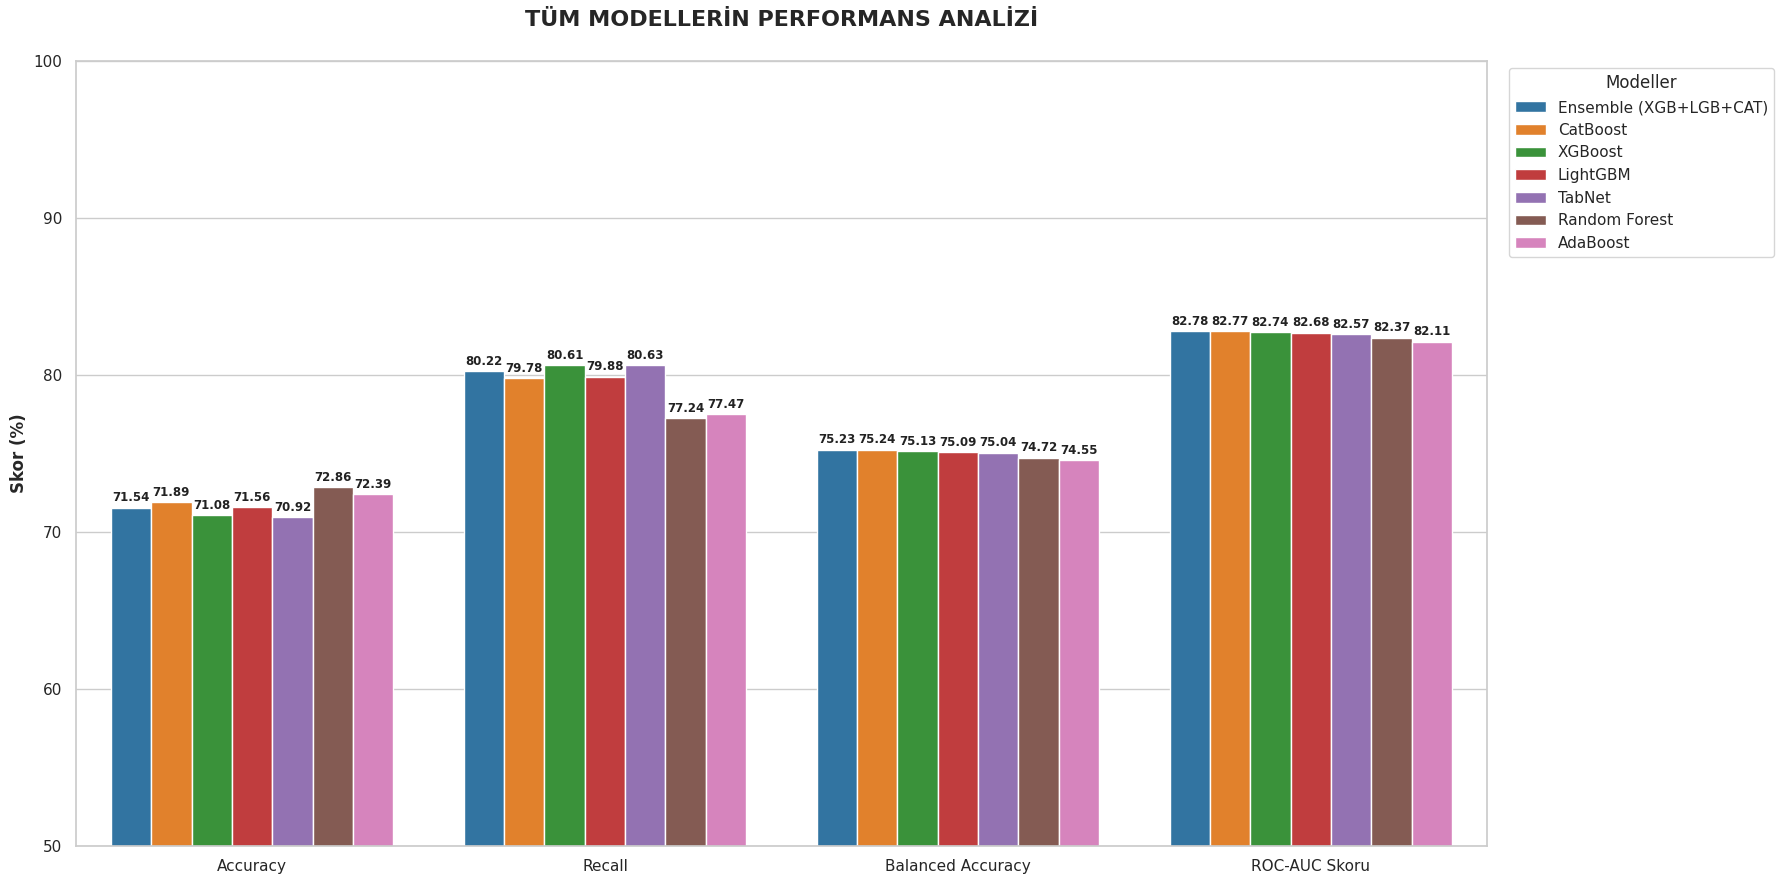

Model,Accuracy,Recall,Balanced Accuracy,ROC-AUC Skoru
Ensemble (XGB+LGB+CAT),71.54%,80.22%,75.23%,82.78%
CatBoost,71.89%,79.78%,75.24%,82.77%
XGBoost,71.08%,80.61%,75.13%,82.74%
LightGBM,71.56%,79.88%,75.09%,82.68%
TabNet,70.92%,80.63%,75.04%,82.57%
Random Forest,72.86%,77.24%,74.72%,82.37%
AdaBoost,72.39%,77.47%,74.55%,82.11%


In [33]:
final_results = {
    "Model": ["Ensemble (XGB+LGB+CAT)", "CatBoost", "LightGBM", "XGBoost", "TabNet", "Random Forest", "AdaBoost"],
    "Accuracy": [
        accuracy_score(y_test, ensemble_pred) * 100,
        accuracy_score(y_test, cat_pred) * 100,
        accuracy_score(y_test, lgb_model.predict(X_test)) * 100,
        accuracy_score(y_test, best_xgb.predict(X_test)) * 100,
        accuracy_score(y_test_np, tabnet_pred) * 100,
        accuracy_score(y_test, best_rf.predict(X_test)) * 100,
        accuracy_score(y_test, best_ada.predict(X_test)) * 100
    ],
    "Recall": [
        recall_score(y_test, ensemble_pred) * 100,
        recall_score(y_test, cat_pred) * 100,
        recall_score(y_test, lgb_model.predict(X_test)) * 100,
        recall_score(y_test, best_xgb.predict(X_test)) * 100,
        recall_score(y_test_np, tabnet_pred) * 100,
        recall_score(y_test, best_rf.predict(X_test)) * 100,
        recall_score(y_test, best_ada.predict(X_test)) * 100
    ],
    "Balanced Accuracy": [
        balanced_accuracy_score(y_test, ensemble_pred) * 100,
        balanced_accuracy_score(y_test, cat_pred) * 100,
        balanced_accuracy_score(y_test, lgb_model.predict(X_test)) * 100,
        balanced_accuracy_score(y_test, best_xgb.predict(X_test)) * 100,
        balanced_accuracy_score(y_test_np, tabnet_pred) * 100,
        balanced_accuracy_score(y_test, best_rf.predict(X_test)) * 100,
        balanced_accuracy_score(y_test, best_ada.predict(X_test)) * 100
    ],
    "ROC-AUC Skoru": [
        roc_auc_score(y_test, ensemble_proba) * 100,
        roc_auc_score(y_test, cat_proba) * 100,
        roc_auc_score(y_test, lgb_model.predict_proba(X_test)[:, 1]) * 100,
        roc_auc_score(y_test, best_xgb.predict_proba(X_test)[:, 1]) * 100,
        roc_auc_score(y_test_np, tabnet_proba) * 100,
        roc_auc_score(y_test, best_rf.predict_proba(X_test)[:, 1]) * 100,
        roc_auc_score(y_test, best_ada.predict_proba(X_test)[:, 1]) * 100
    ]
}

final_df = pd.DataFrame(final_results).sort_values(by="ROC-AUC Skoru", ascending=False).reset_index(drop=True)

df_melted = final_df.melt(id_vars="Model", var_name="Metrik", value_name="Skor (%)")
plt.figure(figsize=(18, 9))
sns.set_theme(style="whitegrid")
ax = sns.barplot(x="Metrik", y="Skor (%)", hue="Model", data=df_melted, palette="tab10")

for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(format(height, '.2f'), 
                    (p.get_x() + p.get_width() / 2., height), 
                    ha='center', va='center', 
                    xytext=(0, 7), 
                    textcoords='offset points',
                    fontsize=8.5, fontweight='bold', color='#222222')

plt.title("TÜM MODELLERİN PERFORMANS ANALİZİ", fontsize=16, fontweight="bold", pad=25)
plt.ylim(50, 100)
plt.ylabel("Skor (%)", fontweight="bold", fontsize=12)
plt.xlabel("")
plt.legend(title="Modeller", bbox_to_anchor=(1.01, 1), loc='upper left', frameon=True)
plt.tight_layout()
plt.show()

sayisal_kolonlar = ["Accuracy", "Recall", "Balanced Accuracy", "ROC-AUC Skoru"]
styled_table = (final_df.style
    .background_gradient(cmap='Blues', subset=sayisal_kolonlar)
    .format("{:.2f}%", subset=sayisal_kolonlar)
    .set_properties(**{'text-align': 'center', 'font-weight': 'bold', 'border': '1px solid #dee2e6'})
    .set_table_styles([{'selector': 'th', 'props': [('background-color', '#1f2d3d'), ('color', 'white'), ('font-size', '14px'), ('text-align', 'center')]},
        {'selector': 'caption', 'props': [('caption-side', 'top'), ('font-size', '16px'), ('font-weight', 'bold'), ('margin-bottom', '12px')]}])
    .hide(axis="index")
    .set_caption("Model Performans Tablosu"))

display(styled_table)

# My Data

## Low Risk

In [34]:
my_data = {
    "HighBP": 0.0,               
    "HighChol": 0.0,             
    "CholCheck": 1.0,            
    "BMI": 27.0,                 
    "Smoker": 1.0,               
    "Stroke": 0.0,               
    "HeartDiseaseorAttack": 0.0, 
    "PhysActivity": 0.0,         
    "Fruits": 0.0,               
    "Veggies": 0.0,              
    "HvyAlcoholConsump": 0.0,    
    "AnyHealthcare": 1.0,        
    "NoDocbcCost": 0.0,          
    "GenHlth": 2.0,              
    "MentHlth": 20.0,            
    "PhysHlth": 3.0,             
    "DiffWalk": 0.0,             
    "Sex": 1.0,                  
    "Age": 1.0,                  
    "Education": 5.0,            
    "Income": 0.0                
}

my_df = pd.DataFrame([my_data])
my_df = my_df[[col for col in X_train.columns if col in my_df.columns]]

models = {
    "Ensemble": ensemble_model,
    "CatBoost": cat_model,
    "LightGBM": lgb_model,
    "XGBoost": best_xgb,
    "Random Forest": best_rf,
    "AdaBoost": best_ada,
    "Tabnet"  : tabnet_model
}

for name, model in models.items():
    X_input = my_df.values if name.lower() == "tabnet" else my_df

    pred = model.predict(X_input)[0]
    prob = model.predict_proba(X_input)[0][1] * 100
    
    sonuc = "RİSKLİ" if pred == 1 else "SAĞLIKLI"
    
    print(f"Model: {name}")
    print(f"Karar: {sonuc}")
    print(f"Hastalık Olasılığı: %{prob:.2f}")
    print("-" * 35)

Model: Ensemble
Karar: SAĞLIKLI
Hastalık Olasılığı: %4.56
-----------------------------------
Model: CatBoost
Karar: SAĞLIKLI
Hastalık Olasılığı: %4.28
-----------------------------------
Model: LightGBM
Karar: SAĞLIKLI
Hastalık Olasılığı: %5.71
-----------------------------------
Model: XGBoost
Karar: SAĞLIKLI
Hastalık Olasılığı: %3.70
-----------------------------------
Model: Random Forest
Karar: SAĞLIKLI
Hastalık Olasılığı: %8.38
-----------------------------------
Model: AdaBoost
Karar: SAĞLIKLI
Hastalık Olasılığı: %29.29
-----------------------------------
Model: Tabnet
Karar: SAĞLIKLI
Hastalık Olasılığı: %2.10
-----------------------------------


 ==================== XGBoost SHAP Analizi ====================


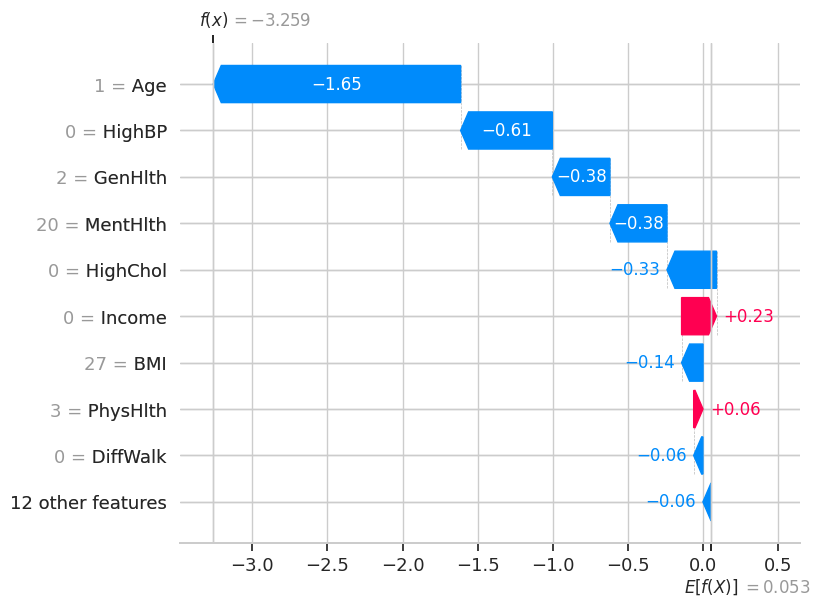

 ==================== LightGBM SHAP Analizi ====================


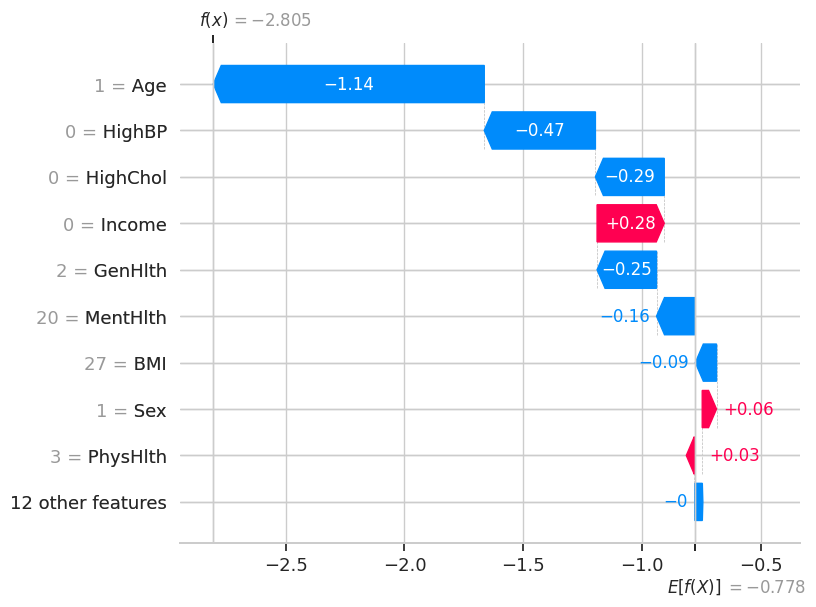

 ==================== CatBoost SHAP Analizi ====================


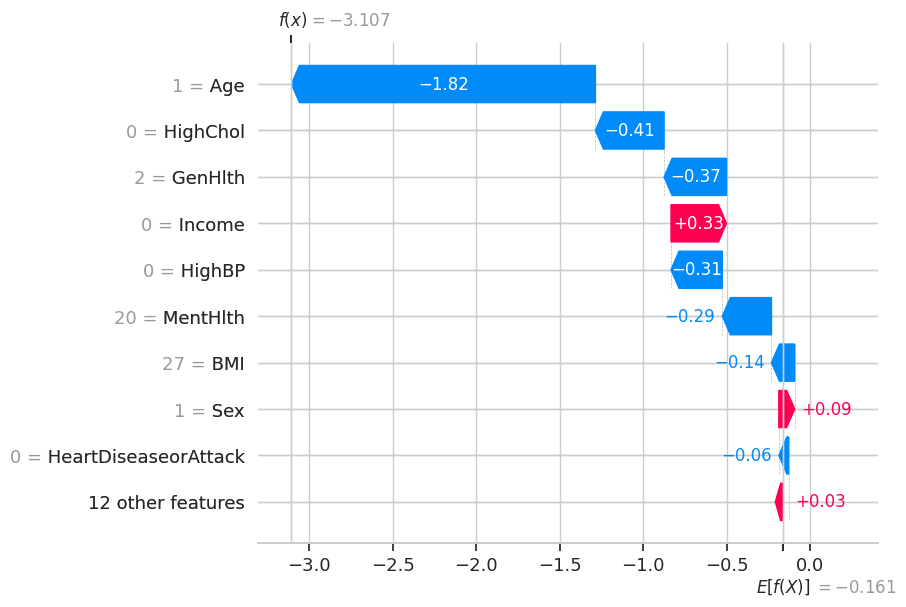

 ==================== Random Forest SHAP Analizi ====================


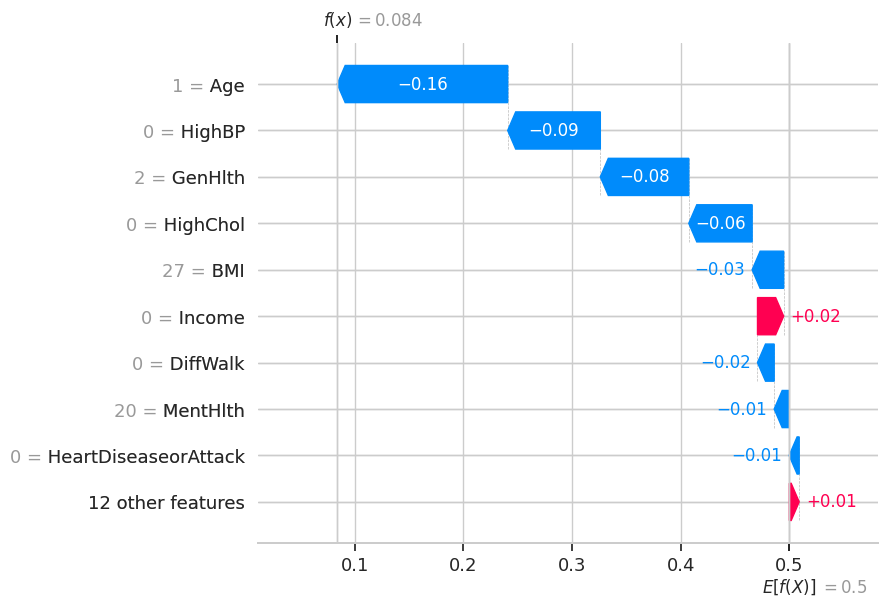

In [35]:
shap_models = {
    "XGBoost": best_xgb,
    "LightGBM": lgb_model,
    "CatBoost": cat_model,
    "Random Forest": best_rf
}

for name, model in shap_models.items():
    print(f" { "=" * 20 } {name} SHAP Analizi { "=" * 20 }")
    
    explainer = shap.TreeExplainer(model)
    shap_values = explainer(my_df)
    
    if len(shap_values.shape) == 3:
        single_shap = shap_values[0, :, 1]
    else:
        single_shap = shap_values[0]
    plt.close("all")
    plt.figure(figsize=(10, 6))
    
    shap.plots.waterfall(single_shap, max_display=10)
    plt.show()

## High Risk

In [36]:
my_data_risk = {
    "HighBP": 1.0,              
    "HighChol": 1.0,            
    "CholCheck": 0.0,           
    "BMI": 38.0,                 
    "Smoker": 1.0,               
    "Stroke": 0.0,               
    "HeartDiseaseorAttack": 1.0, 
    "PhysActivity": 0.0,         
    "Fruits": 0.0,               
    "Veggies": 0.0,             
    "HvyAlcoholConsump": 0.0,    
    "AnyHealthcare": 1.0,        
    "NoDocbcCost": 0.0,          
    "GenHlth": 5.0,              
    "MentHlth": 5.0,             
    "PhysHlth": 15.0,            
    "DiffWalk": 1.0,             
    "Sex": 0.0,                  
    "Age": 11.0,                 
    "Education": 3.0,            
    "Income": 3.0            
    
}
my_df_risk = pd.DataFrame([my_data_risk])
my_df_risk = my_df_risk[[col for col in X_train.columns if col in my_df_risk.columns]]

models = {
    "Ensemble": ensemble_model,
    "CatBoost": cat_model,
    "LightGBM": lgb_model,
    "XGBoost": best_xgb,
    "Random Forest": best_rf,
    "AdaBoost": best_ada,
    "Tabnet"  : tabnet_model
}

for name, model in models.items():
    X_input = my_df_risk.values if name.lower() == "tabnet" else my_df_risk

    pred = model.predict(X_input)[0]
    prob = model.predict_proba(X_input)[0][1] * 100
    
    sonuc = "RİSKLİ" if pred == 1 else "SAĞLIKLI"
    
    print(f"Model: {name}")
    print(f"Karar: {sonuc}")
    print(f"Hastalık Olasılığı: %{prob:.2f}")
    print("-" * 35)

Model: Ensemble
Karar: RİSKLİ
Hastalık Olasılığı: %85.78
-----------------------------------
Model: CatBoost
Karar: RİSKLİ
Hastalık Olasılığı: %80.61
-----------------------------------
Model: LightGBM
Karar: RİSKLİ
Hastalık Olasılığı: %89.27
-----------------------------------
Model: XGBoost
Karar: RİSKLİ
Hastalık Olasılığı: %87.45
-----------------------------------
Model: Random Forest
Karar: RİSKLİ
Hastalık Olasılığı: %85.72
-----------------------------------
Model: AdaBoost
Karar: RİSKLİ
Hastalık Olasılığı: %64.27
-----------------------------------
Model: Tabnet
Karar: RİSKLİ
Hastalık Olasılığı: %90.35
-----------------------------------


-------------------------------------------------- XGBoost --------------------------------------------------


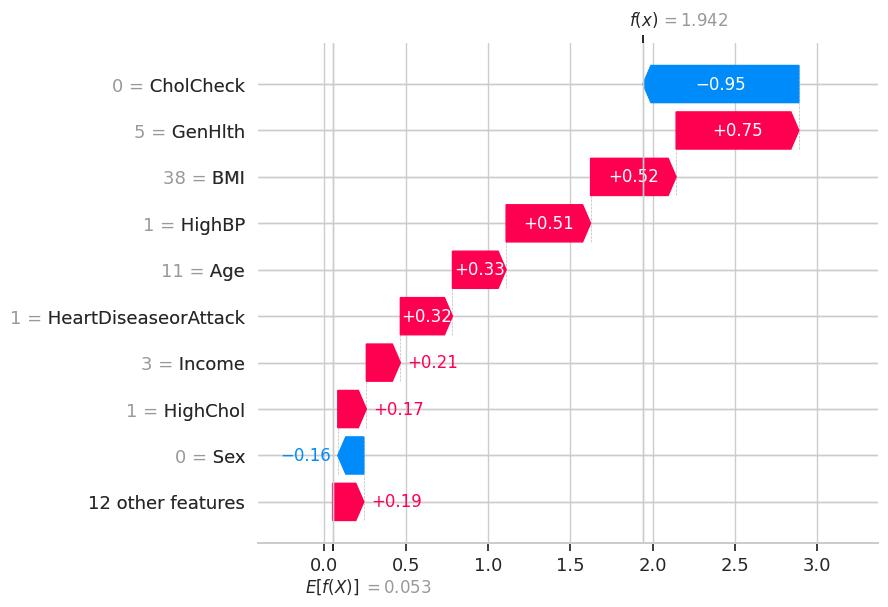

-------------------------------------------------- LightGBM --------------------------------------------------


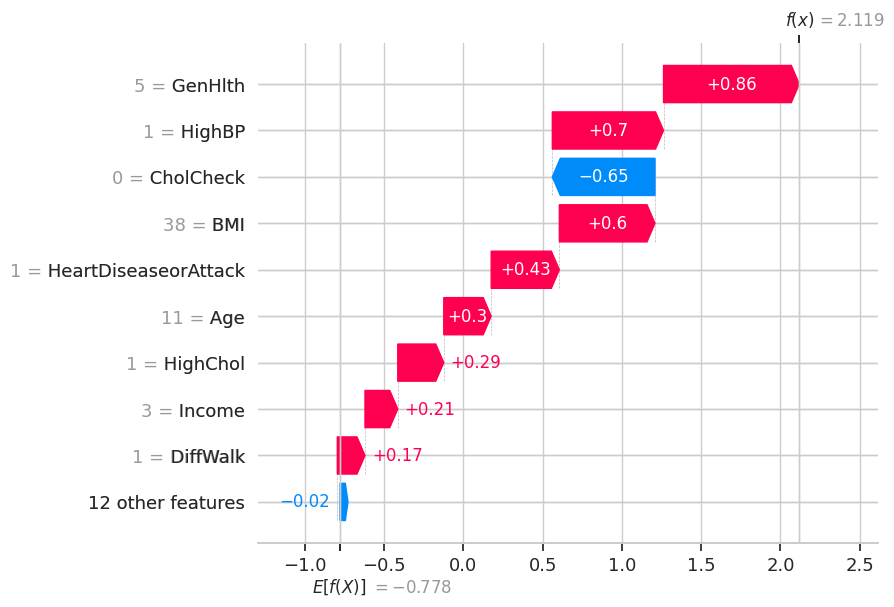

-------------------------------------------------- CatBoost --------------------------------------------------


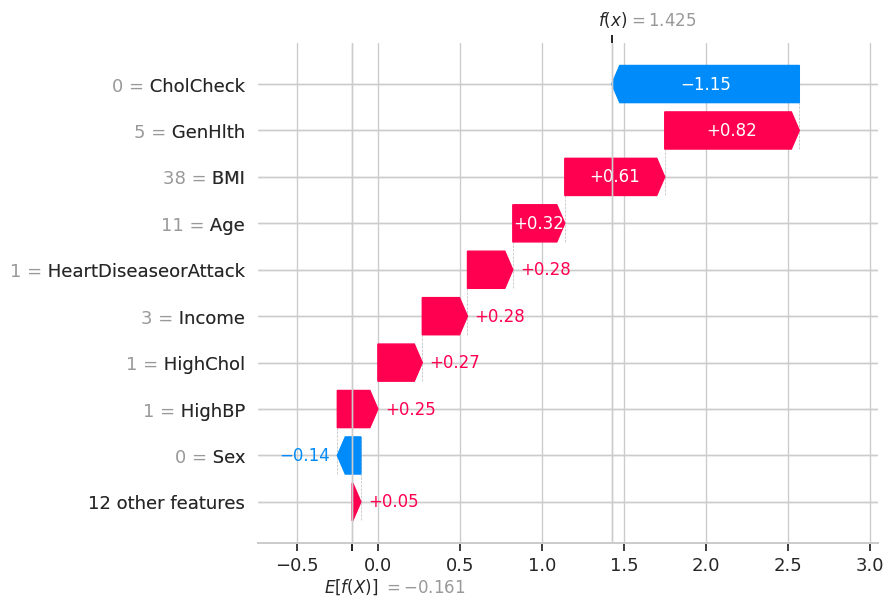

-------------------------------------------------- Random Forest --------------------------------------------------


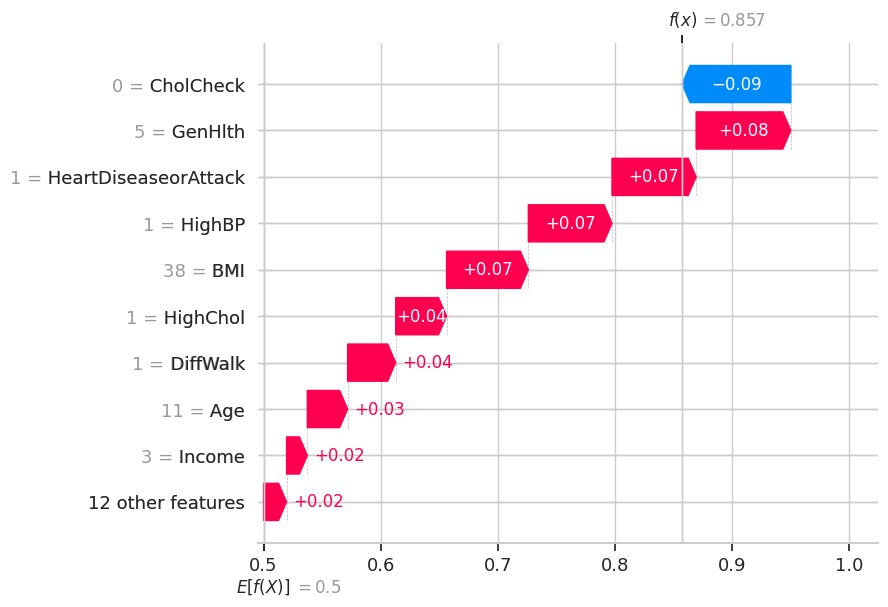

In [37]:
shap_models_riskli = {
    "XGBoost": best_xgb,
    "LightGBM": lgb_model,
    "CatBoost": cat_model,
    "Random Forest": best_rf
}

for name, model in shap_models_riskli.items():
    print(f"{ "-" * 50 } {name} { "-" * 50 }")
    
    explainer = shap.TreeExplainer(model)
    shap_values = explainer(my_df_risk)
    
    if len(shap_values.shape) == 3:
        single_shap = shap_values[0, :, 1]
    else:
        single_shap = shap_values[0]
        
    
    plt.close("all")
    plt.figure(figsize=(10, 6))
    
    shap.plots.waterfall(single_shap, max_display=10)
    plt.show()

## Mid Risk

In [38]:
my_data_medium = {
    "HighBP": 1.0,          
    "HighChol": 0.0,            
    "CholCheck": 1.0,          
    "BMI": 29.5,                
    "Smoker": 0.0,               
    "Stroke": 0.0,               
    "HeartDiseaseorAttack": 0.0, 
    "PhysActivity": 1.0,        
    "Fruits": 1.0,             
    "Veggies": 1.0,           
    "HvyAlcoholConsump": 0.0,   
    "AnyHealthcare": 1.0,       
    "NoDocbcCost": 0.0,       
    "GenHlth": 3.0,             
    "MentHlth": 2.0,           
    "PhysHlth": 2.0,           
    "DiffWalk": 0.0,            
    "Sex": 1.0,                 
    "Age": 6.0,                 
    "Education": 4.0,           
    "Income": 4.0               
}

my_df_medium = pd.DataFrame([my_data_medium])
my_df_medium = my_df_medium[[col for col in X_train.columns if col in my_df_medium.columns]]

models = {
    "Ensemble": ensemble_model,
    "CatBoost": cat_model,
    "LightGBM": lgb_model,
    "XGBoost": best_xgb,
    "Random Forest": best_rf,
    "AdaBoost": best_ada,
    "Tabnet" : tabnet_model
}

for name, model in models.items():
    X_input = my_df_medium.values if name.lower() == "tabnet" else my_df_medium

    pred = model.predict(X_input)[0]
    prob = model.predict_proba(X_input)[0][1] * 100
    
    sonuc = "RİSKLİ" if pred == 1 else "SAĞLIKLI"
    
    print(f"Model: {name}")
    print(f"Karar: {sonuc}")
    print(f"Hastalık Olasılığı: %{prob:.2f}")
    print("-" * 35)

Model: Ensemble
Karar: RİSKLİ
Hastalık Olasılığı: %51.15
-----------------------------------
Model: CatBoost
Karar: RİSKLİ
Hastalık Olasılığı: %50.46
-----------------------------------
Model: LightGBM
Karar: RİSKLİ
Hastalık Olasılığı: %51.13
-----------------------------------
Model: XGBoost
Karar: RİSKLİ
Hastalık Olasılığı: %51.86
-----------------------------------
Model: Random Forest
Karar: RİSKLİ
Hastalık Olasılığı: %50.42
-----------------------------------
Model: AdaBoost
Karar: RİSKLİ
Hastalık Olasılığı: %52.84
-----------------------------------
Model: Tabnet
Karar: RİSKLİ
Hastalık Olasılığı: %53.47
-----------------------------------


 -------------------------------------------------- XGBoost -------------------------------------------------- 


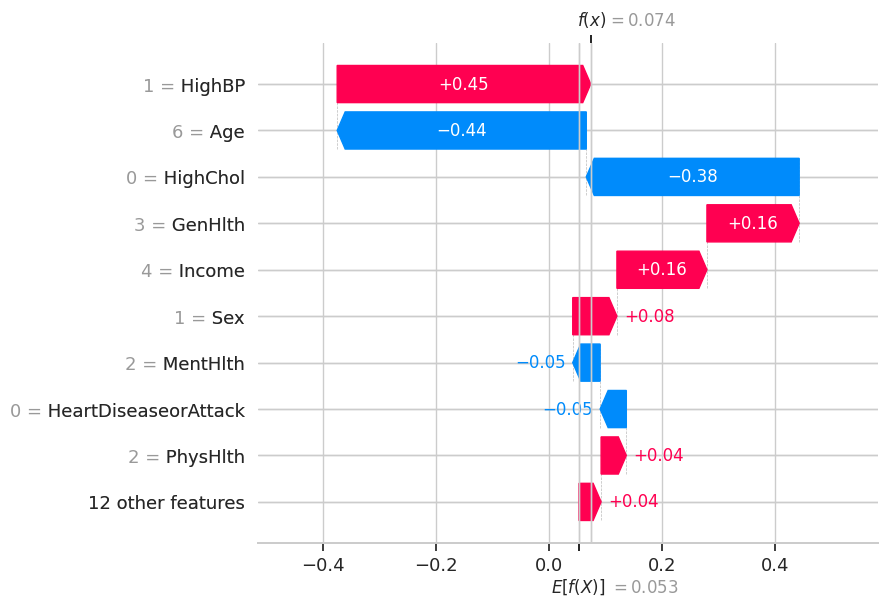

 -------------------------------------------------- LightGBM -------------------------------------------------- 


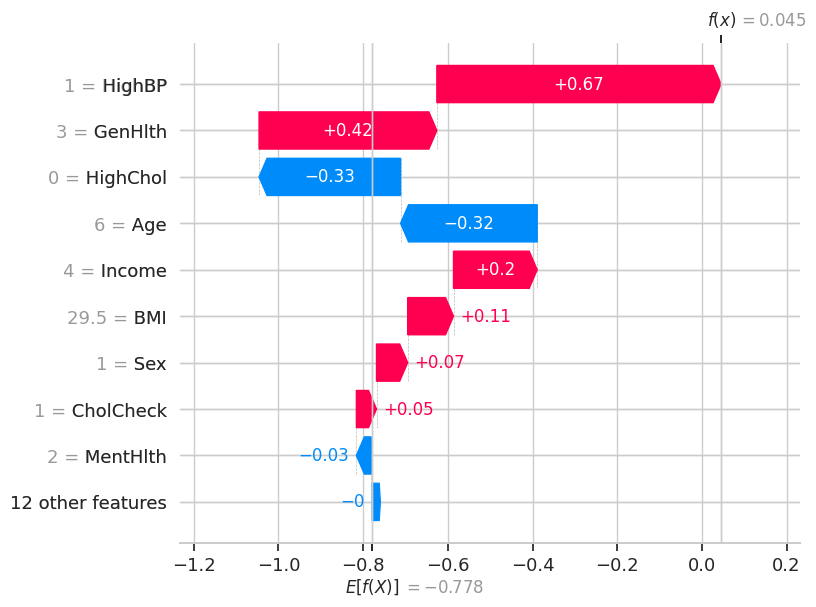

 -------------------------------------------------- CatBoost -------------------------------------------------- 


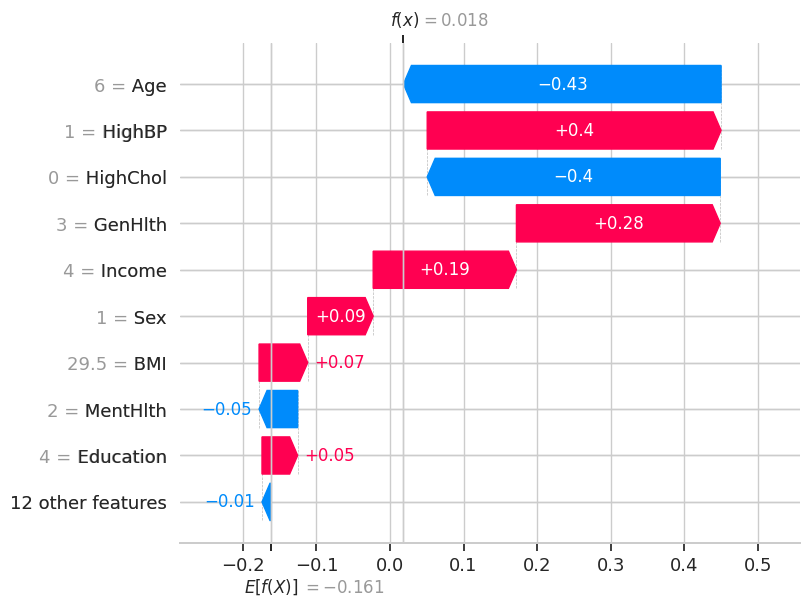

 -------------------------------------------------- Random Forest -------------------------------------------------- 


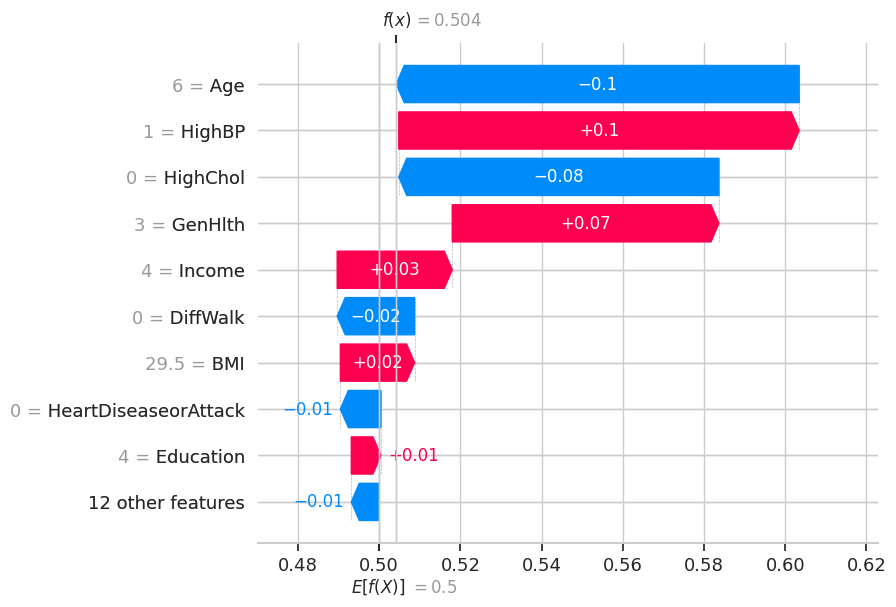

In [39]:
shap_models_medium = {
    "XGBoost": best_xgb,
    "LightGBM": lgb_model,
    "CatBoost": cat_model,
    "Random Forest": best_rf
}

for name, model in shap_models_medium.items():
    print(f" { "-" * 50 } {name} { "-" * 50 } ")
    
    explainer = shap.TreeExplainer(model)
    shap_values = explainer(my_df_medium)
    
    if len(shap_values.shape) == 3:
        single_shap = shap_values[0, :, 1]
    else:
        single_shap = shap_values[0]
        
    plt.close("all")
    plt.figure(figsize=(10, 6))
    
    shap.plots.waterfall(single_shap, max_display=10)
    plt.show()

In [40]:
my_data_sub_medium = {
    "HighBP": 1.0,              
    "HighChol": 0.0,             
    "CholCheck": 1.0,            
    "BMI": 28.0,                 
    "Smoker": 1.0,               
    "Stroke": 1.0,               
    "HeartDiseaseorAttack": 1.0, 
    "PhysActivity": 0.0,         
    "Fruits": 1.0,               
    "Veggies": 1.0,              
    "HvyAlcoholConsump": 1.0,    
    "AnyHealthcare": 0.0,        
    "NoDocbcCost": 0.0,         
    "GenHlth": 3.0,             
    "MentHlth": 1.0,            
    "PhysHlth": 0.0,            
    "DiffWalk": 0.0,            
    "Sex": 1.0,                 
    "Age": 4.0,                 
    "Education": 5.0,           
    "Income": 5.0               
}

my_df_sub_medium = pd.DataFrame([my_data_sub_medium])
my_df_sub_medium = my_df_sub_medium[[col for col in X_train.columns if col in my_df_sub_medium.columns]]


for name, model in models.items():
    X_input = my_df_sub_medium.values if name.lower() == "tabnet" else my_df_sub_medium

    pred = model.predict(X_input)[0]
    prob = model.predict_proba(X_input)[0][1] * 100
    
    sonuc = "RİSKLİ" if pred == 1 else "SAĞLIKLI"
    
    print(f"Model: {name}")
    print(f"Karar: {sonuc}")
    print(f"Hastalık Olasılığı: %{prob:.2f}")
    print("-" * 35)

Model: Ensemble
Karar: SAĞLIKLI
Hastalık Olasılığı: %39.51
-----------------------------------
Model: CatBoost
Karar: SAĞLIKLI
Hastalık Olasılığı: %32.77
-----------------------------------
Model: LightGBM
Karar: SAĞLIKLI
Hastalık Olasılığı: %39.76
-----------------------------------
Model: XGBoost
Karar: SAĞLIKLI
Hastalık Olasılığı: %46.01
-----------------------------------
Model: Random Forest
Karar: SAĞLIKLI
Hastalık Olasılığı: %36.74
-----------------------------------
Model: AdaBoost
Karar: SAĞLIKLI
Hastalık Olasılığı: %46.72
-----------------------------------
Model: Tabnet
Karar: SAĞLIKLI
Hastalık Olasılığı: %40.94
-----------------------------------


-------------------------------------------------- XGBoost --------------------------------------------------


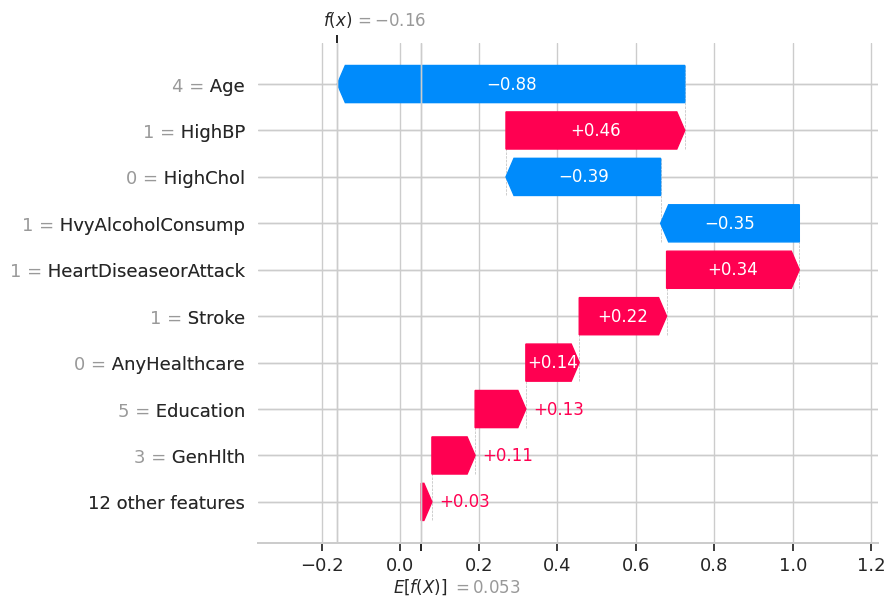

-------------------------------------------------- LightGBM --------------------------------------------------


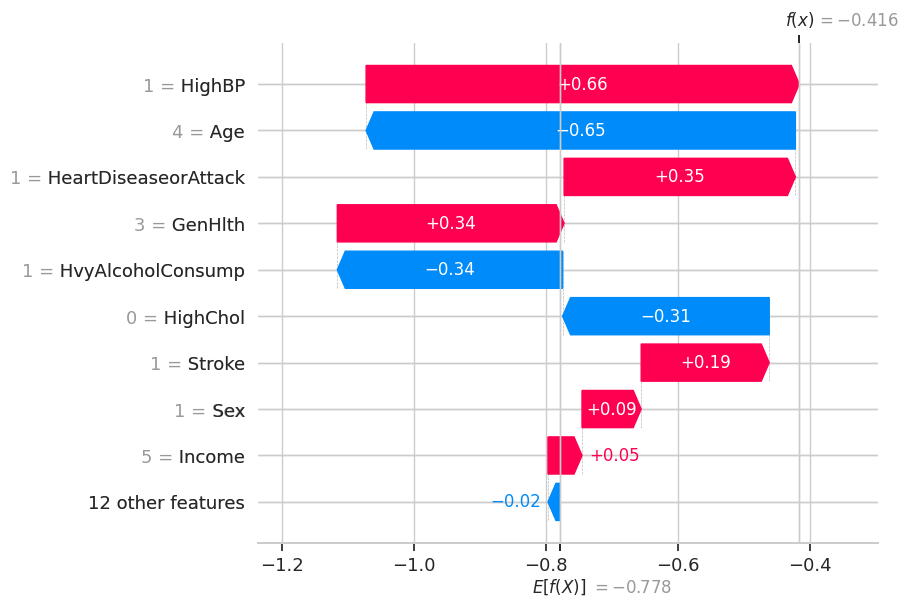

-------------------------------------------------- CatBoost --------------------------------------------------


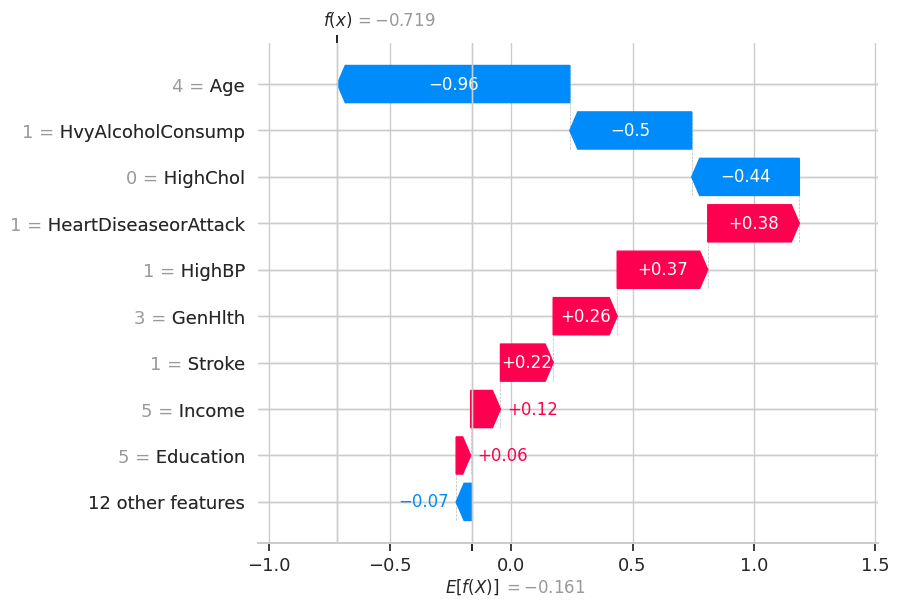

-------------------------------------------------- Random Forest --------------------------------------------------


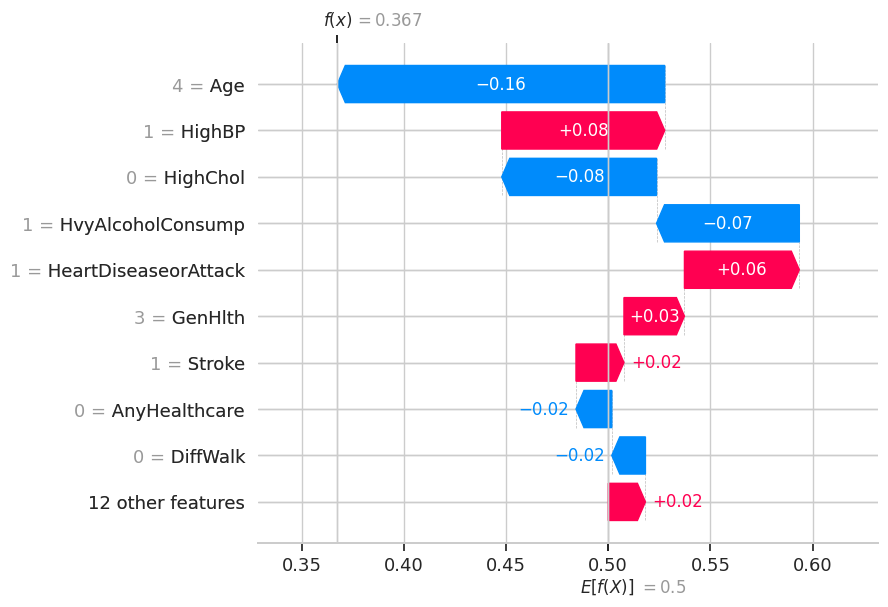

In [41]:
shap_models_sub_medium = {
    "XGBoost": best_xgb,
    "LightGBM": lgb_model,
    "CatBoost": cat_model,
    "Random Forest": best_rf
}

for name, model in shap_models_sub_medium.items():
    print(f"{ "-" * 50 } {name} { "-" * 50 }")
    
    explainer = shap.TreeExplainer(model)
    shap_values = explainer(my_df_sub_medium)
    
    if len(shap_values.shape) == 3:
        single_shap = shap_values[0, :, 1]
    else:
        single_shap = shap_values[0]
        
    plt.close('all')
    plt.figure(figsize=(10, 6))
    
    shap.plots.waterfall(single_shap, max_display=10)
    plt.show()